<a href="https://colab.research.google.com/github/SAMANVI-MEDARAMETLA/NLP/blob/main/Assignment_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# TASK 1: DESIGN A CONTEXT-FREE GRAMMAR FOR ENGLISH SYNTAX

# Install NLTK
!pip install nltk

import nltk
from nltk import CFG
from nltk.parse import ChartParser

# --------------------------------------------------
# STEP 1: DEFINE CONTEXT-FREE GRAMMAR
# --------------------------------------------------

grammar_text = r"""
# Sentence Rules
S -> NP VP
S -> VP
S -> AUX NP VP
S -> WH VP
S -> WH AUX NP VP
S -> S CONJ S
S -> CP

# Noun Phrase Rules
NP -> DET N
NP -> DET ADJP N
NP -> PRON
NP -> N
NP -> NP PP
NP -> NP CONJ NP
NP -> DET N PP
NP -> DET ADJP N PP

# Verb Phrase Rules
VP -> V
VP -> V NP
VP -> V NP NP
VP -> V PP
VP -> V NP PP
VP -> V CP
VP -> AUX VP
VP -> ADV VP
VP -> VP PP
VP -> VP CONJ VP

# Prepositional Phrase Rules
PP -> PREP NP
PP -> PREP PRON
PP -> PREP DET N

# Adjective Phrase Rules
ADJP -> ADJ
ADJP -> ADV ADJ
ADJP -> ADJ PP

# Adverb Phrase Rules
ADVP -> ADV
ADVP -> ADV ADV

# Other Grammar Rules
CP -> COMP S
CP -> COMP NP VP
SBAR -> COMP S
NP -> WH N
VP -> V SBAR
S -> WH AUX VP
S -> NP AUX VP
VP -> V ADVP
NP -> DET N CONJ N
VP -> V NP CONJ NP
PP -> PREP NP PP
S -> AUX NP VP CONJ VP

# Lexicon
DET -> 'the' | 'a' | 'an' | 'this' | 'that' | 'these' | 'those' | 'my' | 'your'

N -> 'student' | 'teacher' | 'exam' | 'timetable' | 'hostel' | 'fee'
N -> 'library' | 'book' | 'room' | 'department' | 'college' | 'portal'
N -> 'assignment' | 'result' | 'attendance' | 'scholarship' | 'receipt'
N -> 'application' | 'placement' | 'semester' | 'form' | 'class'

V -> 'submit' | 'check' | 'show' | 'book' | 'pay' | 'apply'
V -> 'attend' | 'explain' | 'provide' | 'cancel' | 'download'
V -> 'register' | 'send' | 'tell' | 'reserve' | 'crashed'
V -> 'submitted' | 'checked' | 'applied' | 'paid' | 'arrived'

PRON -> 'i' | 'we' | 'you' | 'he' | 'she' | 'they' | 'me' | 'us' | 'them'

PREP -> 'in' | 'on' | 'at' | 'to' | 'from' | 'for'
PREP -> 'near' | 'with' | 'by' | 'after' | 'before'

ADJ -> 'late' | 'pending' | 'available' | 'important' | 'new'
ADJ -> 'old' | 'online' | 'final' | 'previous' | 'current'

ADV -> 'quickly' | 'slowly' | 'today' | 'tomorrow' | 'recently'

AUX -> 'is' | 'are' | 'am' | 'was' | 'were' | 'do' | 'does'
AUX -> 'did' | 'can' | 'could' | 'will' | 'would' | 'should'

CONJ -> 'and' | 'or' | 'but'

WH -> 'what' | 'when' | 'where' | 'who' | 'which' | 'why' | 'how'

COMP -> 'that' | 'whether' | 'if'
"""

grammar = CFG.fromstring(grammar_text)

# --------------------------------------------------
# STEP 2: DISPLAY GRAMMAR RULES
# --------------------------------------------------

print("CONTEXT-FREE GRAMMAR")
print("--------------------")

rules = grammar.productions()

print("Total Grammar Rules:", len(rules))

for rule in rules:
    print(rule)

# --------------------------------------------------
# STEP 3: DISPLAY NON-TERMINALS
# --------------------------------------------------

non_terminals = set()

for rule in rules:
    non_terminals.add(rule.lhs())

print("\nNON-TERMINAL SYMBOLS")
print("--------------------")

for symbol in sorted(non_terminals, key=str):
    print(symbol)

# --------------------------------------------------
# STEP 4: DISPLAY TERMINALS / LEXICON
# --------------------------------------------------

terminals = set(grammar._lexical_index.keys())

print("\nLEXICON / TERMINAL WORDS")
print("------------------------")

print("Total Unique Words:", len(terminals))

for word in sorted(terminals):
    print(word)

# --------------------------------------------------
# STEP 5: DISPLAY START SYMBOL
# --------------------------------------------------

print("\nSTART SYMBOL")
print("------------")

print(grammar.start())

# --------------------------------------------------
# STEP 6: PARSE SENTENCES
# --------------------------------------------------

parser = ChartParser(grammar)

sentences = [
    "the student submitted the assignment",
    "the teacher checked the timetable",
    "the student applied for a hostel",
    "the student booked a room",
    "the teacher showed the result"
]

print("\nSENTENCE PARSING RESULTS")
print("------------------------")

for sentence in sentences:

    print("\nSentence:", sentence)

    words = sentence.lower().split()

    try:
        trees = list(parser.parse(words))

        if trees:
            print("Status: Accepted")
            print("Number of Parse Trees:", len(trees))

            print("Parse Tree:")
            trees[0].pretty_print()

        else:
            print("Status: Rejected")

    except ValueError:
        print("Status: Rejected - Unknown word")


# --------------------------------------------------
# STEP 7: CONSTITUENCY TESTS
# --------------------------------------------------

print("\nCONSTITUENCY TESTS")
print("------------------")

# Substitution Test
print("\n1. Substitution Test")

original = "the student submitted the assignment"
substitution = "she submitted the assignment"

print("Original Sentence:", original)
print("Substituted Sentence:", substitution)
print("Result: 'The student' is replaced by 'She'.")

# Movement Test
print("\n2. Movement Test")

original = "the student submitted the assignment in the library"
movement = "in the library the student submitted the assignment"

print("Original Sentence:", original)
print("Moved Sentence:", movement)
print("Result: The phrase 'in the library' is moved.")

# Coordination Test
print("\n3. Coordination Test")

coordination = "the student and the teacher submitted the forms"

print("Sentence:", coordination)
print("Result: Two noun phrases are joined using 'and'.")


# --------------------------------------------------
# STEP 8: RECURSIVE RULE DEMONSTRATION
# --------------------------------------------------

print("\nRECURSIVE GRAMMAR RULES")
print("-----------------------")

print("NP -> NP PP")
print("PP -> PREP NP")
print("S -> S CONJ S")

print("\nThese rules allow phrases and sentences to grow recursively.")


# --------------------------------------------------
# STEP 9: FINAL SUMMARY
# --------------------------------------------------

print("\nFINAL SUMMARY")
print("-------------")

print("Grammar Type: Context-Free Grammar")
print("Start Symbol:", grammar.start())
print("Total Production Rules:", len(rules))
print("Total Lexicon Words:", len(terminals))
print("Total Non-Terminals:", len(non_terminals))

print("\nTASK 1 EXECUTED SUCCESSFULLY!")

CONTEXT-FREE GRAMMAR
--------------------
Total Grammar Rules: 158
S -> NP VP
S -> VP
S -> AUX NP VP
S -> WH VP
S -> WH AUX NP VP
S -> S CONJ S
S -> CP
NP -> DET N
NP -> DET ADJP N
NP -> PRON
NP -> N
NP -> NP PP
NP -> NP CONJ NP
NP -> DET N PP
NP -> DET ADJP N PP
VP -> V
VP -> V NP
VP -> V NP NP
VP -> V PP
VP -> V NP PP
VP -> V CP
VP -> AUX VP
VP -> ADV VP
VP -> VP PP
VP -> VP CONJ VP
PP -> PREP NP
PP -> PREP PRON
PP -> PREP DET N
ADJP -> ADJ
ADJP -> ADV ADJ
ADJP -> ADJ PP
ADVP -> ADV
ADVP -> ADV ADV
CP -> COMP S
CP -> COMP NP VP
SBAR -> COMP S
NP -> WH N
VP -> V SBAR
S -> WH AUX VP
S -> NP AUX VP
VP -> V ADVP
NP -> DET N CONJ N
VP -> V NP CONJ NP
PP -> PREP NP PP
S -> AUX NP VP CONJ VP
DET -> 'the'
DET -> 'a'
DET -> 'an'
DET -> 'this'
DET -> 'that'
DET -> 'these'
DET -> 'those'
DET -> 'my'
DET -> 'your'
N -> 'student'
N -> 'teacher'
N -> 'exam'
N -> 'timetable'
N -> 'hostel'
N -> 'fee'
N -> 'library'
N -> 'book'
N -> 'room'
N -> 'department'
N -> 'college'
N -> 'portal'
N -> 'assignme

In [ ]:
# TASK 2: CONTEXT-FREE RULES, DERIVATIONS AND PARSE TREES

!pip install nltk

import nltk
from nltk import CFG, ChartParser, Tree
from nltk.tree import Tree

# --------------------------------------------------
# STEP 1: DEFINE THE GRAMMAR
# --------------------------------------------------

grammar_text = r"""
S -> NP VP
S -> VP

NP -> DET N
NP -> NP PP
NP -> NP CONJ NP

VP -> V
VP -> V NP
VP -> V PP
VP -> VP PP

PP -> PREP NP

DET -> 'the' | 'a'
N -> 'student' | 'assignment' | 'teacher' | 'timetable'
N -> 'hostel' | 'room' | 'forms' | 'library'
N -> 'telescope' | 'seminar'

V -> 'submitted' | 'checked' | 'applied'
V -> 'booked' | 'saw' | 'book'

PREP -> 'for' | 'with' | 'near'

CONJ -> 'and'
"""

grammar = CFG.fromstring(grammar_text)

parser = ChartParser(grammar)

print("GRAMMAR RULES")
print("-------------")

for rule in grammar.productions():
    print(rule)

print("\nTotal Production Rules:", len(grammar.productions()))


# --------------------------------------------------
# STEP 2: DEFINE FIVE SENTENCES
# --------------------------------------------------

sentences = [
    "the student submitted the assignment",
    "the teacher checked the timetable",
    "the student applied for a hostel",
    "the student booked a room",
    "the student and the teacher submitted the forms"
]


# --------------------------------------------------
# STEP 3: GENERATE LEFTMOST DERIVATION
# --------------------------------------------------

def leftmost_derivation(tree):

    current = [tree.label()]

    steps = [" ".join(current)]

    def expand(node):

        nonlocal current

        if isinstance(node, str):
            return

        # Find leftmost non-terminal
        for i, symbol in enumerate(current):

            if symbol == node.label():

                children = []

                for child in node:
                    if isinstance(child, Tree):
                        children.append(child.label())
                    else:
                        children.append(child)

                current = (
                    current[:i] +
                    children +
                    current[i+1:]
                )

                steps.append(" ".join(current))
                break

        for child in node:
            if isinstance(child, Tree):
                expand(child)

    expand(tree)

    return steps


# --------------------------------------------------
# STEP 4: GENERATE RIGHTMOST DERIVATION
# --------------------------------------------------

def rightmost_derivation(tree):

    current = [tree.label()]

    steps = [" ".join(current)]

    def expand(node):

        nonlocal current

        if isinstance(node, str):
            return

        # Find rightmost non-terminal
        for i in range(len(current)-1, -1, -1):

            if current[i] == node.label():

                children = []

                for child in node:
                    if isinstance(child, Tree):
                        children.append(child.label())
                    else:
                        children.append(child)

                current = (
                    current[:i] +
                    children +
                    current[i+1:]
                )

                steps.append(" ".join(current))
                break

        for child in reversed(node):
            if isinstance(child, Tree):
                expand(child)

    expand(tree)

    return steps


# --------------------------------------------------
# STEP 5: CALCULATE TREE MEASUREMENTS
# --------------------------------------------------

def tree_height(tree):

    if isinstance(tree, str):
        return 0

    return 1 + max(
        tree_height(child) for child in tree
    )


def count_nodes(tree):

    if isinstance(tree, str):
        return 1

    return 1 + sum(
        count_nodes(child) for child in tree
    )


def count_rules(tree):

    if isinstance(tree, str):
        return 0

    return 1 + sum(
        count_rules(child) for child in tree
    )


# --------------------------------------------------
# STEP 6: PARSE FIVE SENTENCES
# --------------------------------------------------

results = []

print("\nFIVE SENTENCES AND THEIR PARSE TREES")
print("====================================")

for number, sentence in enumerate(sentences, 1):

    words = sentence.split()

    trees = list(parser.parse(words))

    print("\nSENTENCE", number)
    print("Sentence:", sentence)

    if len(trees) == 0:
        print("No parse tree found")
        continue

    tree = trees[0]

    # Leftmost derivation
    print("\nLEFTMOST DERIVATION")

    left_steps = leftmost_derivation(tree)

    for step in left_steps:
        print("=>", step)

    # Rightmost derivation
    print("\nRIGHTMOST DERIVATION")

    right_steps = rightmost_derivation(tree)

    for step in right_steps:
        print("=>", step)

    # Bracketed notation
    print("\nBRACKETED NOTATION")
    print(tree)

    # Tree diagram
    print("\nPARSE TREE DIAGRAM")
    tree.pretty_print()

    # Measurements
    height = tree_height(tree)
    nodes = count_nodes(tree)
    rules = count_rules(tree)

    print("Tree Height:", height)
    print("Number of Nodes:", nodes)
    print("Rule Applications:", rules)

    results.append({
        "Sentence": sentence,
        "Height": height,
        "Nodes": nodes,
        "Rule Applications": rules
    })


# --------------------------------------------------
# STEP 7: DISPLAY MEASUREMENT TABLE
# --------------------------------------------------

import pandas as pd

print("\nPARSE TREE MEASUREMENT TABLE")

df = pd.DataFrame(results)

display(df)


# --------------------------------------------------
# STEP 8: STRUCTURAL AMBIGUITY - EXAMPLE 1
# --------------------------------------------------

ambiguous_sentence = "the student saw the teacher with the telescope"

print("\nSTRUCTURAL AMBIGUITY - EXAMPLE 1")
print("Sentence:", ambiguous_sentence)

ambiguity_trees = list(
    parser.parse(ambiguous_sentence.split())
)

print("Number of Parse Trees:", len(ambiguity_trees))

for i, tree in enumerate(ambiguity_trees, 1):

    print("\nPARSE", i)

    print("Bracketed Notation:")
    print(tree)

    tree.pretty_print()


# --------------------------------------------------
# STEP 9: STRUCTURAL AMBIGUITY - EXAMPLE 2
# --------------------------------------------------

ambiguous_sentence2 = (
    "book the room near the library for the seminar"
)

print("\nSTRUCTURAL AMBIGUITY - EXAMPLE 2")
print("Sentence:", ambiguous_sentence2)

ambiguity_trees2 = list(
    parser.parse(ambiguous_sentence2.split())
)

print("Number of Parse Trees:", len(ambiguity_trees2))

for i, tree in enumerate(ambiguity_trees2, 1):

    print("\nPARSE", i)

    print("Bracketed Notation:")
    print(tree)

    tree.pretty_print()


# --------------------------------------------------
# STEP 10: TEST SENTENCE MEMBERSHIP IN L(G)
# --------------------------------------------------

def check_sentence(sentence):

    words = sentence.lower().split()

    trees = list(parser.parse(words))

    if trees:
        print(sentence, "-> ACCEPTED")
    else:
        print(sentence, "-> REJECTED")


print("\nSENTENCE MEMBERSHIP TEST")
print("------------------------")

check_sentence("the student submitted the assignment")

check_sentence("the teacher checked the timetable")

check_sentence("the student assignment submitted")


# --------------------------------------------------
# STEP 11: FINAL SUMMARY
# --------------------------------------------------

print("\nFINAL SUMMARY")
print("-------------")

print("Total Sentences Tested:", len(sentences))

print("Total Ambiguous Parses - Example 1:",
      len(ambiguity_trees))

print("Total Ambiguous Parses - Example 2:",
      len(ambiguity_trees2))

print("Grammar Type: Context-Free Grammar")
print("Parsing Method: Chart Parsing")

print("\nTASK 2 COMPLETED SUCCESSFULLY!")

GRAMMAR RULES
-------------
S -> NP VP
S -> VP
NP -> DET N
NP -> NP PP
NP -> NP CONJ NP
VP -> V
VP -> V NP
VP -> V PP
VP -> VP PP
PP -> PREP NP
DET -> 'the'
DET -> 'a'
N -> 'student'
N -> 'assignment'
N -> 'teacher'
N -> 'timetable'
N -> 'hostel'
N -> 'room'
N -> 'forms'
N -> 'library'
N -> 'telescope'
N -> 'seminar'
V -> 'submitted'
V -> 'checked'
V -> 'applied'
V -> 'booked'
V -> 'saw'
V -> 'book'
PREP -> 'for'
PREP -> 'with'
PREP -> 'near'
CONJ -> 'and'

Total Production Rules: 32

FIVE SENTENCES AND THEIR PARSE TREES

SENTENCE 1
Sentence: the student submitted the assignment

LEFTMOST DERIVATION
=> S
=> NP VP
=> DET N VP
=> the N VP
=> the student VP
=> the student V NP
=> the student submitted NP
=> the student submitted DET N
=> the student submitted the N
=> the student submitted the assignment

RIGHTMOST DERIVATION
=> S
=> NP VP
=> NP V NP
=> NP V DET N
=> NP V DET assignment
=> NP V the assignment
=> NP submitted the assignment
=> DET N submitted the assignment
=> DET student 

,Sentence,Height,Nodes,Rule Applications
0,the student submitted the assignment,4,14,9
1,the teacher checked the timetable,4,14,9
2,the student applied for a hostel,5,18,12
3,the student booked a room,4,14,9
4,the student and the teacher submitted the forms,4,22,14



STRUCTURAL AMBIGUITY - EXAMPLE 1
Sentence: the student saw the teacher with the telescope
Number of Parse Trees: 2

PARSE 1
Bracketed Notation:
(S
  (NP (DET the) (N student))
  (VP
    (VP (V saw) (NP (DET the) (N teacher)))
    (PP (PREP with) (NP (DET the) (N telescope)))))
                     S                                    
      _______________|_________                            
     |                         VP                         
     |                _________|__________                 
     |               VP                   PP              
     |            ___|___             ____|___             
     NP          |       NP          |        NP          
  ___|_____      |    ___|_____      |     ___|______      
DET        N     V  DET        N    PREP DET         N    
 |         |     |   |         |     |    |          |     
the     student saw the     teacher with the     telescope


PARSE 2
Bracketed Notation:
(S
  (NP (DET the) (N student))
  (VP

In [ ]:
# TASK 3: SENTENCE-LEVEL CONSTRUCTIONS
# Declarative, Imperative, Yes/No Questions and Wh-Questions

!pip install nltk

import nltk
from nltk import CFG, ChartParser
from nltk.tree import Tree

# --------------------------------------------------
# STEP 1: DEFINE THE GRAMMAR
# --------------------------------------------------

grammar_text = r"""

# DECLARATIVE SENTENCES
S -> NP VP
S -> NP AUX VP

# IMPERATIVE SENTENCES
S -> VP

# YES / NO QUESTIONS
S -> AUX NP VP

# WH QUESTIONS
S -> WH VP
S -> WH AUX NP VP
S -> WH AUX NP V

# NOUN PHRASE RULES
NP -> DET N
NP -> DET ADJ N
NP -> PRON
NP -> N
NP -> DET N REL

# VERB PHRASE RULES
VP -> V
VP -> V NP
VP -> V PP
VP -> AUX V
VP -> AUX V PP
VP -> V CP
VP -> V VP
VP -> VP CONJ VP
VP -> V NP PP

# PREPOSITIONAL PHRASE
PP -> PREP NP

# SUBORDINATE CLAUSES
CP -> COMP S
CP -> COMP NP VP

# RELATIVE CLAUSES
REL -> RELPRO AUX V
REL -> RELPRO V
REL -> RELPRO NP VP

# COORDINATION
S -> S CONJ S
NP -> NP CONJ NP

# LEXICON
DET -> 'the' | 'a' | 'an'
N -> 'student' | 'teacher' | 'assignment'
N -> 'form' | 'exam' | 'exams' | 'fees'
N -> 'hostel' | 'library' | 'room'
N -> 'application' | 'seminar' | 'timetable'
N -> 'teacher' | 'result' | 'class'

V -> 'submitted' | 'submit' | 'checked'
V -> 'check' | 'book' | 'booked'
V -> 'paid' | 'pay' | 'attend'
V -> 'attending' | 'postponed' | 'held' | 'be'
V -> 'say' | 'said' | 'cancel'
V -> 'cancelled' | 'show' | 'showed'
V -> 'tell' | 'provide' | 'download'

AUX -> 'is' | 'are' | 'was' | 'were'
AUX -> 'do' | 'does' | 'did' | 'can'
AUX -> 'could' | 'will' | 'would' | 'should'

PRON -> 'i' | 'you' | 'we' | 'they'
PRON -> 'he' | 'she' | 'it'

PREP -> 'in' | 'on' | 'at' | 'to'
PREP -> 'for' | 'from' | 'near' | 'with'

ADJ -> 'late' | 'new' | 'final' | 'available'

CONJ -> 'and' | 'or' | 'but'

WH -> 'what' | 'when' | 'where' | 'who'
WH -> 'why' | 'how' | 'which'

COMP -> 'that' | 'whether' | 'if'

RELPRO -> 'that' | 'who' | 'which'
"""

grammar = CFG.fromstring(grammar_text)

parser = ChartParser(grammar)

print("GRAMMAR CREATED SUCCESSFULLY")
print("--------------------------------")

print("Total Production Rules:",
      len(grammar.productions()))


# --------------------------------------------------
# STEP 2: DEFINE SENTENCES
# --------------------------------------------------

sentence_groups = {

    "1. DECLARATIVE SENTENCES": [
        "the student submitted the assignment",
        "the teacher checked the timetable"
    ],

    "2. IMPERATIVE SENTENCES": [
        "submit the form",
        "check the timetable"
    ],

    "3. YES / NO QUESTIONS": [
        "can the student submit the form",
        "does the teacher check the assignment"
    ],

    "4. WH QUESTIONS - SUBJECT": [
        "who submitted the assignment",
        "who checked the timetable"
    ],

    "5. WH QUESTIONS - NON-SUBJECT": [
        "what did the student submit",
        "which form did the teacher check"
    ],

    "6. SUBORDINATE CLAUSES": [
        "the student said that the exam was postponed",
        "the teacher said that the student submitted the form"
    ],

    "7. RELATIVE CLAUSES": [
        "the exams that were postponed will be held",
        "the student that submitted the form attended class"
    ],

    "8. COORDINATION": [
        "the student and the teacher submitted the forms",
        "the student submitted the assignment and paid the fees"
    ]
}


# --------------------------------------------------
# STEP 3: PARSE ALL SENTENCES
# --------------------------------------------------

all_results = []

print("\nSENTENCE PARSING RESULTS")
print("========================")

for category, sentences in sentence_groups.items():

    print("\n", category)
    print("-" * 55)

    for sentence in sentences:

        words = sentence.split()

        print("\nSentence:", sentence)

        try:

            trees = list(parser.parse(words))

            if trees:

                print("Status: ACCEPTED")
                print("Number of Parse Trees:", len(trees))

                tree = trees[0]

                print("\nBracketed Notation:")
                print(tree)

                print("\nParse Tree Diagram:")
                tree.pretty_print()

                all_results.append({
                    "Category": category,
                    "Sentence": sentence,
                    "Status": "Accepted",
                    "Parse Trees": len(trees)
                })

            else:

                print("Status: REJECTED")

                all_results.append({
                    "Category": category,
                    "Sentence": sentence,
                    "Status": "Rejected",
                    "Parse Trees": 0
                })

        except ValueError:

            print("Status: REJECTED - Unknown word")

            all_results.append({
                "Category": category,
                "Sentence": sentence,
                "Status": "Rejected",
                "Parse Trees": 0
            })


# --------------------------------------------------
# STEP 4: DEMONSTRATE AUXILIARY INVERSION
# --------------------------------------------------

print("\nAUXILIARY INVERSION")
print("===================")

declarative = "the student is attending the exam"
question = "is the student attending the exam"

print("Declarative:", declarative)
print("Yes/No Question:", question)

print("\nDeclarative Structure:")
print("S -> NP AUX VP")

print("\nQuestion Structure:")
print("S -> AUX NP VP")

print("Auxiliary 'is' moves before the subject.")


# --------------------------------------------------
# STEP 5: DEMONSTRATE WH-MOVEMENT
# --------------------------------------------------

print("\nWH-MOVEMENT")
print("===========")

normal_sentence = "the student submitted what"
wh_question = "what did the student submit"

print("Normal Structure:", normal_sentence)
print("Wh-Question:", wh_question)

print("\nGrammar Rule:")
print("S -> WH AUX NP V")

print("The word 'what' represents the missing object position.")


# --------------------------------------------------
# STEP 6: DEMONSTRATE SUBORDINATE CLAUSE
# --------------------------------------------------

print("\nSUBORDINATE CLAUSE")
print("==================")

subordinate_sentence = (
    "the student said that the exam was postponed"
)

print("Sentence:", subordinate_sentence)

subordinate_trees = list(
    parser.parse(subordinate_sentence.split())
)

if subordinate_trees:

    print("Subordinate Clause Accepted")

    subordinate_trees[0].pretty_print()

else:

    print("No parse found")


# --------------------------------------------------
# STEP 7: DEMONSTRATE RELATIVE CLAUSE
# --------------------------------------------------

print("\nRELATIVE CLAUSE")
print("===============")

relative_sentence = (
    "the exams that were postponed will be held"
)

print("Sentence:", relative_sentence)

relative_trees = list(
    parser.parse(relative_sentence.split())
)

if relative_trees:

    print("Relative Clause Accepted")

    relative_trees[0].pretty_print()

else:

    print("No parse found")


# --------------------------------------------------
# STEP 8: DEMONSTRATE COORDINATION
# --------------------------------------------------

print("\nCOORDINATION")
print("============")

coordination_sentence = (
    "the student and the teacher submitted the forms"
)

print("Sentence:", coordination_sentence)

coordination_trees = list(
    parser.parse(coordination_sentence.split())
)

if coordination_trees:

    print("Coordination Accepted")

    coordination_trees[0].pretty_print()

else:

    print("No parse found")


# --------------------------------------------------
# STEP 9: COMPARE SENTENCE CONSTRUCTIONS
# --------------------------------------------------

import pandas as pd

comparison = pd.DataFrame({

    "Sentence Construction": [
        "Declarative",
        "Imperative",
        "Yes/No Question",
        "Wh-Question",
        "Subordinate Clause",
        "Relative Clause",
        "Coordination"
    ],

    "Main Grammar Rule": [
        "S -> NP VP",
        "S -> VP",
        "S -> AUX NP VP",
        "S -> WH AUX NP VP",
        "CP -> COMP S",
        "NP -> DET N REL",
        "S -> S CONJ S"
    ],

    "Purpose": [
        "Provides information",
        "Gives instructions",
        "Asks for confirmation",
        "Requests specific information",
        "Adds dependent information",
        "Describes a noun",
        "Joins grammatical units"
    ]
})

print("\nSENTENCE CONSTRUCTION COMPARISON")

display(comparison)


# --------------------------------------------------
# STEP 10: FINAL RESULTS
# --------------------------------------------------

results_df = pd.DataFrame(all_results)

print("\nFINAL PARSING RESULTS")
print("=====================")

display(results_df)

accepted = sum(
    result["Status"] == "Accepted"
    for result in all_results
)

rejected = len(all_results) - accepted

print("\nTotal Sentences:", len(all_results))
print("Accepted Sentences:", accepted)
print("Rejected Sentences:", rejected)

print("\nTASK 3 COMPLETED SUCCESSFULLY!")

GRAMMAR CREATED SUCCESSFULLY
--------------------------------
Total Production Rules: 117

SENTENCE PARSING RESULTS

 1. DECLARATIVE SENTENCES
-------------------------------------------------------

Sentence: the student submitted the assignment
Status: ACCEPTED
Number of Parse Trees: 1

Bracketed Notation:
(S
  (NP (DET the) (N student))
  (VP (V submitted) (NP (DET the) (N assignment))))

Parse Tree Diagram:
                    S                       
      ______________|______                  
     |                     VP               
     |               ______|___              
     NP             |          NP           
  ___|_____         |       ___|______       
DET        N        V     DET         N     
 |         |        |      |          |      
the     student submitted the     assignment


Sentence: the teacher checked the timetable
Status: ACCEPTED
Number of Parse Trees: 1

Bracketed Notation:
(S
  (NP (DET the) (N teacher))
  (VP (V checked) (NP (DET the) (N 

ValueError: Grammar does not cover some of the input words: "'forms'".

STEP 1: ORIGINAL CFG CREATED
Number of Rules: 32

STEP 2: AGREEMENT-AWARE CFG CREATED
Number of Rules: 56

STEP 5: PARSING COMPARISON


,Sentence,Expected,Original CFG,Agreement-Aware CFG
0,the student submits the form,Grammatical,Accepted,Accepted
1,the students submit the forms,Grammatical,Accepted,Accepted
2,she checks the timetable,Grammatical,Accepted,Accepted
3,they attend the class,Grammatical,Accepted,Accepted
4,this student pays the fee,Grammatical,Accepted,Accepted
5,these students submit applications,Grammatical,Rejected,Accepted
6,the students submits the form,Ungrammatical,Accepted,Rejected
7,the student submit the form,Ungrammatical,Accepted,Rejected
8,these student submits the form,Ungrammatical,Accepted,Rejected
9,this students submit the form,Ungrammatical,Accepted,Rejected



STEP 6: ACCURACY COMPARISON
Original CFG Accuracy: 41.67 %
Agreement-Aware CFG Accuracy: 100.0 %

STEP 7: RULE EXPLOSION
Person Values: 3
Number Values: 2
Case Values: 3
Gender Values: 2
Total Feature Combinations: 36
Illustrative Base Rules: 45
Worst-Case Expanded Rules: 1620
Note: This is a theoretical upper-bound example.

STEP 8: FEATURE UNIFICATION
Example 1: The student submits
Agreement: True

Example 2: The students submits
Agreement: False

STEP 9: AGREEMENT-AWARE PARSE TREE
Sentence: the student submits the form
Status: ACCEPTED

Bracketed Notation:
(S
  (NP_3SG (DET_ANY the) (N_SG student))
  (VP_3SG (V_3SG submits) (NP_OBJ (DET_ANY the) (N_SG form))))

Parse Tree:
                          S                       
           _______________|_______                 
          |                     VP_3SG            
          |                _______|______          
        NP_3SG            |            NP_OBJ     
    ______|_______        |        ______|_____    
DET_A

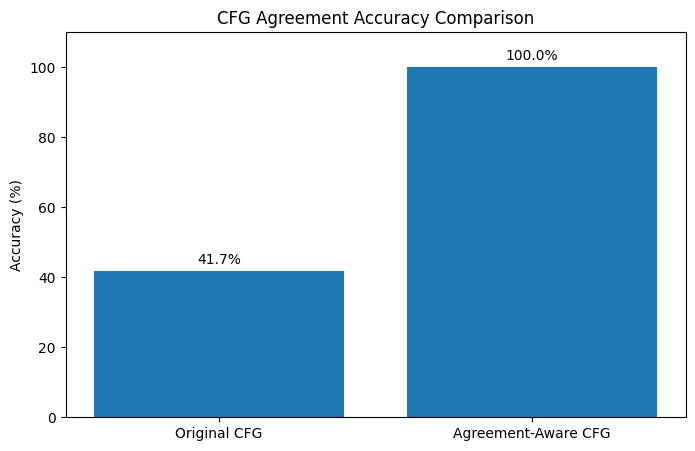


FINAL SUMMARY
Original CFG Rules: 32
Agreement-Aware CFG Rules: 56
Total Test Sentences: 12
Grammatical Sentences: 6
Ungrammatical Sentences: 6
Original CFG Accuracy: 41.67 %
Agreement-Aware CFG Accuracy: 100.0 %

TASK 4 COMPLETED SUCCESSFULLY!


In [ ]:
# ==========================================================
# TASK 4: AGREEMENT IN CONTEXT-FREE GRAMMAR
# ==========================================================

import nltk
import pandas as pd
import matplotlib.pyplot as plt

from nltk import CFG, ChartParser

# ----------------------------------------------------------
# STEP 1: DEFINE ORIGINAL CFG (WITHOUT AGREEMENT)
# ----------------------------------------------------------

original_grammar = CFG.fromstring("""
S -> NP VP
NP -> DET N | PRON
VP -> V NP | V

DET -> 'the' | 'this' | 'these'
N -> 'student' | 'students' | 'form' | 'forms'
N -> 'timetable' | 'class' | 'fee' | 'application'
N -> 'applications' | 'teacher'

PRON -> 'she' | 'they' | 'her' | 'he'

V -> 'submit' | 'submits' | 'check' | 'checks'
V -> 'attend' | 'attends' | 'pay' | 'pays'
V -> 'submitted' | 'called'
""")

original_parser = ChartParser(original_grammar)

print("STEP 1: ORIGINAL CFG CREATED")
print("Number of Rules:",
      len(original_grammar.productions()))


# ----------------------------------------------------------
# STEP 2: DEFINE AGREEMENT-AWARE CFG
# ----------------------------------------------------------

agreement_grammar = CFG.fromstring("""
S -> NP_3SG VP_3SG
S -> NP_PL VP_PL
S -> NP_PAST VP_PAST

NP_3SG -> DET_SG N_SG
NP_3SG -> DET_ANY N_SG
NP_3SG -> PRON_3SG

NP_PL -> DET_PL N_PL
NP_PL -> DET_ANY N_PL
NP_PL -> PRON_PL
NP_PL -> N_PL

NP_PAST -> DET_ANY N_SG
NP_PAST -> PRON_SUBJ

NP_OBJ -> DET_ANY N_SG
NP_OBJ -> DET_ANY N_PL
NP_OBJ -> DET_SG N_SG
NP_OBJ -> DET_PL N_PL
NP_OBJ -> PRON_OBJ
NP_OBJ -> N_PL

VP_3SG -> V_3SG NP_OBJ
VP_3SG -> V_3SG

VP_PL -> V_PL NP_OBJ
VP_PL -> V_PL

VP_PAST -> V_PAST NP_OBJ
VP_PAST -> V_PAST

DET_SG -> 'this'
DET_PL -> 'these'
DET_ANY -> 'the'

N_SG -> 'student' | 'form' | 'timetable'
N_SG -> 'class' | 'fee' | 'application'
N_SG -> 'teacher'

N_PL -> 'students' | 'forms' | 'applications'

PRON_3SG -> 'she' | 'he'
PRON_PL -> 'they'
PRON_SUBJ -> 'she' | 'he' | 'they'
PRON_OBJ -> 'her' | 'him' | 'them'

V_3SG -> 'submits' | 'checks' | 'attends' | 'pays'
V_PL -> 'submit' | 'check' | 'attend' | 'pay'
V_PAST -> 'submitted' | 'called'
""")

agreement_parser = ChartParser(agreement_grammar)

print("\nSTEP 2: AGREEMENT-AWARE CFG CREATED")
print("Number of Rules:",
      len(agreement_grammar.productions()))


# ----------------------------------------------------------
# STEP 3: DEFINE TEST SENTENCES
# ----------------------------------------------------------

test_sentences = [
    ("the student submits the form", "Grammatical"),
    ("the students submit the forms", "Grammatical"),
    ("she checks the timetable", "Grammatical"),
    ("they attend the class", "Grammatical"),
    ("this student pays the fee", "Grammatical"),
    ("these students submit applications", "Grammatical"),

    ("the students submits the form", "Ungrammatical"),
    ("the student submit the form", "Ungrammatical"),
    ("these student submits the form", "Ungrammatical"),
    ("this students submit the form", "Ungrammatical"),
    ("her submitted the application", "Ungrammatical"),
    ("the teacher called he", "Ungrammatical")
]


# ----------------------------------------------------------
# STEP 4: CREATE PARSING FUNCTION
# ----------------------------------------------------------

def parse_sentence(parser, sentence):

    words = sentence.lower().split()

    try:
        trees = list(parser.parse(words))
        return "Accepted" if trees else "Rejected"

    except ValueError:
        return "Rejected"


# ----------------------------------------------------------
# STEP 5: TEST BOTH GRAMMARS
# ----------------------------------------------------------

results = []

for sentence, expected in test_sentences:

    original_result = parse_sentence(
        original_parser, sentence
    )

    agreement_result = parse_sentence(
        agreement_parser, sentence
    )

    results.append({
        "Sentence": sentence,
        "Expected": expected,
        "Original CFG": original_result,
        "Agreement-Aware CFG": agreement_result
    })


df = pd.DataFrame(results)

print("\nSTEP 5: PARSING COMPARISON")
display(df)


# ----------------------------------------------------------
# STEP 6: CALCULATE ACCURACY
# ----------------------------------------------------------

def calculate_accuracy(column):

    correct = 0

    for _, row in df.iterrows():

        expected_result = (
            "Accepted"
            if row["Expected"] == "Grammatical"
            else "Rejected"
        )

        if row[column] == expected_result:
            correct += 1

    return correct / len(df) * 100


original_accuracy = calculate_accuracy("Original CFG")

agreement_accuracy = calculate_accuracy(
    "Agreement-Aware CFG"
)

print("\nSTEP 6: ACCURACY COMPARISON")

print("Original CFG Accuracy:",
      round(original_accuracy, 2), "%")

print("Agreement-Aware CFG Accuracy:",
      round(agreement_accuracy, 2), "%")


# ----------------------------------------------------------
# STEP 7: RULE EXPLOSION CALCULATION
# ----------------------------------------------------------

person = 3
number = 2
case = 3
gender = 2

combinations = person * number * case * gender

base_rules = 45

worst_case_rules = base_rules * combinations

print("\nSTEP 7: RULE EXPLOSION")

print("Person Values:", person)
print("Number Values:", number)
print("Case Values:", case)
print("Gender Values:", gender)

print("Total Feature Combinations:", combinations)

print("Illustrative Base Rules:", base_rules)

print("Worst-Case Expanded Rules:",
      worst_case_rules)

print("Note: This is a theoretical upper-bound example.")


# ----------------------------------------------------------
# STEP 8: FEATURE-BASED AGREEMENT CHECKING
# ----------------------------------------------------------

def unify_features(subject, verb):

    for feature in ["NUM", "PER"]:

        if subject.get(feature) != verb.get(feature):
            return False

    return True


print("\nSTEP 8: FEATURE UNIFICATION")

subject1 = {"NUM": "SG", "PER": 3}
verb1 = {"NUM": "SG", "PER": 3}

subject2 = {"NUM": "PL", "PER": 3}
verb2 = {"NUM": "SG", "PER": 3}

print("Example 1: The student submits")
print("Agreement:", unify_features(subject1, verb1))

print("\nExample 2: The students submits")
print("Agreement:", unify_features(subject2, verb2))


# ----------------------------------------------------------
# STEP 9: DISPLAY PARSE TREE
# ----------------------------------------------------------

print("\nSTEP 9: AGREEMENT-AWARE PARSE TREE")

example = "the student submits the form"

trees = list(
    agreement_parser.parse(example.split())
)

if trees:

    print("Sentence:", example)
    print("Status: ACCEPTED")

    print("\nBracketed Notation:")
    print(trees[0])

    print("\nParse Tree:")
    trees[0].pretty_print()

else:
    print("No valid parse found")


# ----------------------------------------------------------
# STEP 10: VISUALIZE ACCURACY
# ----------------------------------------------------------

plt.figure(figsize=(8, 5))

models = ["Original CFG", "Agreement-Aware CFG"]

accuracies = [
    original_accuracy,
    agreement_accuracy
]

bars = plt.bar(models, accuracies)

plt.title("CFG Agreement Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 110)

for bar, accuracy in zip(bars, accuracies):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        accuracy + 2,
        f"{accuracy:.1f}%",
        ha="center"
    )

plt.show()


# ----------------------------------------------------------
# STEP 11: FINAL SUMMARY
# ----------------------------------------------------------

print("\nFINAL SUMMARY")
print("=" * 50)

print("Original CFG Rules:",
      len(original_grammar.productions()))

print("Agreement-Aware CFG Rules:",
      len(agreement_grammar.productions()))

print("Total Test Sentences:",
      len(test_sentences))

print("Grammatical Sentences: 6")
print("Ungrammatical Sentences: 6")

print("Original CFG Accuracy:",
      round(original_accuracy, 2), "%")

print("Agreement-Aware CFG Accuracy:",
      round(agreement_accuracy, 2), "%")

print("\nTASK 4 COMPLETED SUCCESSFULLY!")

SUBCATEGORIZATION GRAMMAR
S -> NP VP
S -> VP
VP -> V_INTR
VP -> V_TRANS NP
VP -> V_DITRANS NP NP
VP -> V_COMP NP CP
VP -> V_PP PP
VP -> V_TRANS NP PP
NP -> DET N
NP -> PRON
NP -> N
PP -> PREP NP
CP -> COMP S
DET -> 'the'
DET -> 'a'
N -> 'portal'
N -> 'form'
N -> 'receipt'
N -> 'fee'
N -> 'hostel'
N -> 'room'
N -> 'student'
N -> 'process'
N -> 'application'
PRON -> 'me'
PRON -> 'you'
PRON -> 'him'
PRON -> 'her'
V_INTR -> 'crashed'
V_TRANS -> 'submit'
V_TRANS -> 'check'
V_TRANS -> 'book'
V_TRANS -> 'paid'
V_TRANS -> 'place'
V_DITRANS -> 'send'
V_DITRANS -> 'give'
V_COMP -> 'tell'
V_COMP -> 'inform'
V_PP -> 'apply'
PREP -> 'for'
PREP -> 'to'
PREP -> 'in'
COMP -> 'that'

Total Grammar Rules: 43

SUBCATEGORIZATION LEXICON


,type,frame,example
crashed,Intransitive,V,The portal crashed.
submit,Transitive,V + NP,Submit the form.
send,Ditransitive,V + NP + NP,Send me the receipt.
tell,Sentential Complement,V + NP + CP,Tell me that the fee is paid.
apply,PP Complement,V + PP,Apply for a hostel room.
book,Transitive,V + NP,Book a room.



SENTENCE PARSING RESULTS

Sentence: the portal crashed
Expected: Accepted
Parser Result: Accepted
Parse Tree:
          S           
      ____|_______     
     NP           VP  
  ___|____        |    
DET       N     V_INTR
 |        |       |    
the     portal crashed


Sentence: submit the form
Expected: Accepted
Parser Result: Accepted
Parse Tree:
         S          
         |           
         VP         
    _____|___        
   |         NP     
   |      ___|___    
V_TRANS DET      N  
   |     |       |   
 submit the     form


Sentence: send me the receipt
Expected: Accepted
Parser Result: Accepted
Parse Tree:
           S                  
           |                   
           VP                 
     ______|________           
    |      NP       NP        
    |      |     ___|_____     
V_DITRANS PRON DET        N   
    |      |    |         |    
   send    me  the     receipt


Sentence: tell me that the fee crashed
Expected: Accepted
Parser Result: Acce

,Sentence,Expected,Parser Result,Correct
0,the portal crashed,Accepted,Accepted,True
1,submit the form,Accepted,Accepted,True
2,send me the receipt,Accepted,Accepted,True
3,tell me that the fee crashed,Accepted,Accepted,True
4,apply for a hostel,Accepted,Accepted,True
5,book a room,Accepted,Accepted,True
6,submit,Rejected,Rejected,True
7,the portal crashed the form,Rejected,Rejected,True
8,send the receipt,Rejected,Rejected,True
9,apply the hostel,Rejected,Rejected,True



COMPLEMENT AND ADJUNCT


,Sentence,Element,Type,Reason
0,Submit the form,the form,Complement,Selected object of submit
1,The student submitted the form yesterday,yesterday,Adjunct,Provides additional time information
2,Apply for a hostel room,for a hostel room,Complement,Selected PP complement of apply
3,The student submitted the form quickly,quickly,Adjunct,Provides additional manner information



MULTIPLE SUBCATEGORIZATION FRAMES

Verb: book
Frame: book a room
Frame: book the application

Verb: send
Frame: send the receipt
Frame: send me the receipt

Verb: explain
Frame: explain the process
Frame: explain the process to me

RULE COMPLEXITY
Base Grammar Rules: 10
Verb Categories: 5
Additional Categories: 5
Illustrative Total: 15

Separate verb categories increase grammar size.
Feature-based grammar can represent SUBCAT values
without creating many separate verb categories.

PARSING PERFORMANCE
Total Test Sentences: 10
Correct Results: 10
Accuracy: 100.0 %


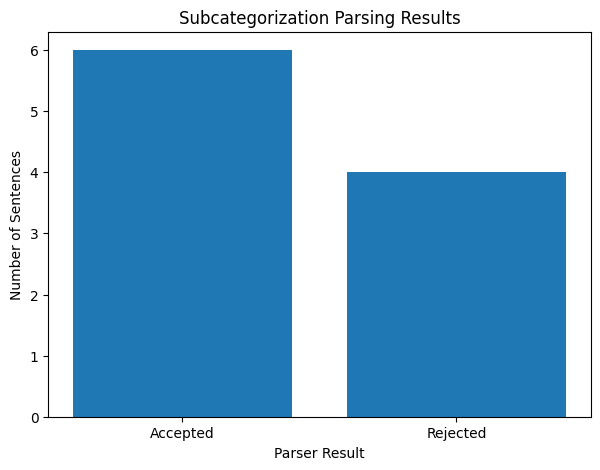


FINAL SUMMARY
Subcategorization Frames: 5
1. Intransitive
2. Transitive
3. Ditransitive
4. Sentential Complement
5. PP Complement
Accepted Sentences: 6
Rejected Sentences: 4
Parsing Accuracy: 100.0 %

TASK 5 COMPLETED SUCCESSFULLY!


In [ ]:
# ==========================================================
# TASK 5: SUBCATEGORIZATION
# ==========================================================

!pip install nltk

import nltk
import pandas as pd
import matplotlib.pyplot as plt

from nltk import CFG, ChartParser

# ----------------------------------------------------------
# STEP 1: DEFINE SUBCATEGORIZATION GRAMMAR
# ----------------------------------------------------------

grammar_text = r"""

# Sentence Rules
S -> NP VP
S -> VP

# Verb Phrase Rules
VP -> V_INTR
VP -> V_TRANS NP
VP -> V_DITRANS NP NP
VP -> V_COMP NP CP
VP -> V_PP PP
VP -> V_TRANS NP PP

# Noun Phrase Rules
NP -> DET N
NP -> PRON
NP -> N

# Prepositional Phrase
PP -> PREP NP

# Complement Clause
CP -> COMP S

# Determiners
DET -> 'the' | 'a'

# Nouns
N -> 'portal' | 'form' | 'receipt'
N -> 'fee' | 'hostel' | 'room'
N -> 'student' | 'process' | 'application'

# Pronouns
PRON -> 'me' | 'you' | 'him' | 'her'

# Verbs - Different Subcategorization Frames
V_INTR -> 'crashed'

V_TRANS -> 'submit' | 'check' | 'book'
V_TRANS -> 'paid' | 'place'

V_DITRANS -> 'send' | 'give'

V_COMP -> 'tell' | 'inform'

V_PP -> 'apply'

# Prepositions
PREP -> 'for' | 'to' | 'in'

# Complementizer
COMP -> 'that'

"""

grammar = CFG.fromstring(grammar_text)

parser = ChartParser(grammar)

print("SUBCATEGORIZATION GRAMMAR")
print("=========================")

for rule in grammar.productions():
    print(rule)

print("\nTotal Grammar Rules:",
      len(grammar.productions()))


# ----------------------------------------------------------
# STEP 2: CREATE SUBCATEGORIZATION LEXICON
# ----------------------------------------------------------

lexicon = {

    "crashed": {
        "type": "Intransitive",
        "frame": "V",
        "example": "The portal crashed."
    },

    "submit": {
        "type": "Transitive",
        "frame": "V + NP",
        "example": "Submit the form."
    },

    "send": {
        "type": "Ditransitive",
        "frame": "V + NP + NP",
        "example": "Send me the receipt."
    },

    "tell": {
        "type": "Sentential Complement",
        "frame": "V + NP + CP",
        "example": "Tell me that the fee is paid."
    },

    "apply": {
        "type": "PP Complement",
        "frame": "V + PP",
        "example": "Apply for a hostel room."
    },

    "book": {
        "type": "Transitive",
        "frame": "V + NP",
        "example": "Book a room."
    }
}

print("\nSUBCATEGORIZATION LEXICON")
print("=========================")

lexicon_df = pd.DataFrame(lexicon).T

display(lexicon_df)


# ----------------------------------------------------------
# STEP 3: DEFINE TEST SENTENCES
# ----------------------------------------------------------

test_sentences = [

    ("the portal crashed", "Accepted"),
    ("submit the form", "Accepted"),
    ("send me the receipt", "Accepted"),
    ("tell me that the fee crashed", "Accepted"),
    ("apply for a hostel", "Accepted"),
    ("book a room", "Accepted"),

    ("submit", "Rejected"),
    ("the portal crashed the form", "Rejected"),
    ("send the receipt", "Rejected"),
    ("apply the hostel", "Rejected")
]


# ----------------------------------------------------------
# STEP 4: PARSE SENTENCES
# ----------------------------------------------------------

results = []

print("\nSENTENCE PARSING RESULTS")
print("========================")

for sentence, expected in test_sentences:

    words = sentence.split()

    try:

        trees = list(parser.parse(words))

        if trees:
            status = "Accepted"
        else:
            status = "Rejected"

    except ValueError:
        status = "Rejected"
        trees = []

    print("\nSentence:", sentence)
    print("Expected:", expected)
    print("Parser Result:", status)

    if trees:

        print("Parse Tree:")
        trees[0].pretty_print()

    results.append({

        "Sentence": sentence,
        "Expected": expected,
        "Parser Result": status,
        "Correct": expected == status

    })


# ----------------------------------------------------------
# STEP 5: DISPLAY RESULTS TABLE
# ----------------------------------------------------------

print("\nFINAL PARSING TABLE")

df = pd.DataFrame(results)

display(df)


# ----------------------------------------------------------
# STEP 6: COMPLEMENT AND ADJUNCT DEMONSTRATION
# ----------------------------------------------------------

print("\nCOMPLEMENT AND ADJUNCT")
print("======================")

examples = [

    {
        "Sentence": "Submit the form",
        "Element": "the form",
        "Type": "Complement",
        "Reason": "Selected object of submit"
    },

    {
        "Sentence": "The student submitted the form yesterday",
        "Element": "yesterday",
        "Type": "Adjunct",
        "Reason": "Provides additional time information"
    },

    {
        "Sentence": "Apply for a hostel room",
        "Element": "for a hostel room",
        "Type": "Complement",
        "Reason": "Selected PP complement of apply"
    },

    {
        "Sentence": "The student submitted the form quickly",
        "Element": "quickly",
        "Type": "Adjunct",
        "Reason": "Provides additional manner information"
    }
]

complement_df = pd.DataFrame(examples)

display(complement_df)


# ----------------------------------------------------------
# STEP 7: TEST MULTIPLE VERB FRAMES
# ----------------------------------------------------------

print("\nMULTIPLE SUBCATEGORIZATION FRAMES")
print("=================================")

multiple_frames = {

    "book": [
        "book a room",
        "book the application"
    ],

    "send": [
        "send the receipt",
        "send me the receipt"
    ],

    "explain": [
        "explain the process",
        "explain the process to me"
    ]

}

for verb, frames in multiple_frames.items():

    print("\nVerb:", verb)

    for frame in frames:
        print("Frame:", frame)


# ----------------------------------------------------------
# STEP 8: RULE EXPLOSION DISCUSSION
# ----------------------------------------------------------

print("\nRULE COMPLEXITY")
print("================")

base_rules = 10
verb_categories = 5

expanded_rules = base_rules + verb_categories

print("Base Grammar Rules:", base_rules)

print("Verb Categories:", verb_categories)

print("Additional Categories:", verb_categories)

print("Illustrative Total:", expanded_rules)

print("\nSeparate verb categories increase grammar size.")
print("Feature-based grammar can represent SUBCAT values")
print("without creating many separate verb categories.")


# ----------------------------------------------------------
# STEP 9: CALCULATE PARSING ACCURACY
# ----------------------------------------------------------

correct = sum(df["Correct"])

accuracy = (correct / len(df)) * 100

print("\nPARSING PERFORMANCE")
print("===================")

print("Total Test Sentences:", len(df))
print("Correct Results:", correct)
print("Accuracy:", round(accuracy, 2), "%")


# ----------------------------------------------------------
# STEP 10: VISUALIZE ACCEPTED AND REJECTED SENTENCES
# ----------------------------------------------------------

counts = df["Parser Result"].value_counts()

plt.figure(figsize=(7, 5))

plt.bar(counts.index, counts.values)

plt.title("Subcategorization Parsing Results")
plt.xlabel("Parser Result")
plt.ylabel("Number of Sentences")

plt.show()


# ----------------------------------------------------------
# STEP 11: FINAL SUMMARY
# ----------------------------------------------------------

print("\nFINAL SUMMARY")
print("============================")

print("Subcategorization Frames: 5")

print("1. Intransitive")
print("2. Transitive")
print("3. Ditransitive")
print("4. Sentential Complement")
print("5. PP Complement")

print("Accepted Sentences:",
      (df["Parser Result"] == "Accepted").sum())

print("Rejected Sentences:",
      (df["Parser Result"] == "Rejected").sum())

print("Parsing Accuracy:", round(accuracy, 2), "%")

print("\nTASK 5 COMPLETED SUCCESSFULLY!")

In [ ]:

# TASK 6: TOP-DOWN PARSING USING RECURSIVE DESCENT

# Install NLTK
!pip -q install nltk

import nltk
from nltk import CFG
from nltk.parse import RecursiveDescentParser

# 1. Define CFG Grammar
grammar = CFG.fromstring("""
S -> NP VP | VP

NP -> DET N NP_EXT | PRON
NP_EXT -> PP NP_EXT |

VP -> V NP VP_EXT | V VP_EXT
VP_EXT -> PP VP_EXT |

PP -> PREP NP

DET -> 'the' | 'a'
N -> 'portal' | 'student' | 'telescope' | 'book' | 'teacher'
PRON -> 'i'
V -> 'crashed' | 'saw' | 'submitted'
PREP -> 'with' | 'near'
""")

# 2. Create Top-Down Parser
parser = RecursiveDescentParser(grammar)

# 3. Test Sentences
sentences = {
    "Unambiguous": "the portal crashed",
    "Ambiguous": "i saw the student with a telescope",
    "Invalid": "the portal crashed the book"
}

# 4. Parse and Display Results
for name, sentence in sentences.items():

    print("\n" + "=" * 60)
    print(name, "SENTENCE")
    print("Input:", sentence)

    tokens = sentence.lower().split()

    try:
        # Generate parse trees
        trees = list(parser.parse(tokens))

        if trees:
            print("\nResult: ACCEPTED")
            print("Number of parse trees:", len(trees))

            for i, tree in enumerate(trees, 1):
                print(f"\nParse Tree {i}:")
                tree.pretty_print()

        else:
            print("\nResult: REJECTED")
            print("No valid parse tree found.")

    except ValueError:
        print("\nResult: REJECTED")
        print("Input contains words not covered by the grammar.")

# 5. Display Grammar
print("\n" + "=" * 60)
print("GRAMMAR RULES")
print(grammar)

# 6. Demonstrate Top-Down Parsing Trace
print("\n" + "=" * 60)
print("TOP-DOWN PARSING TRACE")
print("Sentence: the portal crashed")

trace_parser = RecursiveDescentParser(grammar)
trace_parser.trace(2)

print("\nConclusion:")
print("Top-down parsing starts from S and expands grammar rules.")
print("It uses backtracking to explore alternative grammar rules.")
print("Left recursion is avoided in this grammar.")



Unambiguous SENTENCE
Input: the portal crashed

Result: ACCEPTED
Number of parse trees: 1

Parse Tree 1:
             S                      
       ______|_____________          
      NP                   VP       
  ____|______         _____|____     
DET   N    NP_EXT    V        VP_EXT
 |    |      |       |          |    
the portal  ...   crashed      ...  


Ambiguous SENTENCE
Input: i saw the student with a telescope

Result: ACCEPTED
Number of parse trees: 2

Parse Tree 1:
                      S                                         
  ____________________|____                                      
 |                         VP                                   
 |     ____________________|________________________________     
 |    |                    NP                               |   
 |    |    ________________|__________                      |    
 |    |   |     |                   NP_EXT                  |   
 |    |   |     |               ______|______________

In [ ]:

# TASK 7: EARLEY PARSING ALGORITHM

# Install NLTK
!pip -q install nltk

from collections import defaultdict
import nltk
from nltk import CFG
from nltk.parse import EarleyChartParser

# --------------------------------------------------
# 1. DEFINE GRAMMAR
# --------------------------------------------------

grammar_rules = {
    "S": [["NP", "VP"]],
    "NP": [["DET", "N"]],
    "VP": [["V", "NP", "ADV"]],
    "DET": [["the"]],
    "N": [["student"], ["form"]],
    "V": [["submitted"]],
    "ADV": [["today"]]
}

# --------------------------------------------------
# 2. EARLEY PARSER IMPLEMENTATION
# --------------------------------------------------

def earley_parse(words, grammar):
    n = len(words)
    chart = [set() for _ in range(n + 1)]
    operations = [[] for _ in range(n + 1)]

    # State format: (LHS, RHS, dot_position, start_position)
    start_state = ("START", ("S",), 0, 0)
    chart[0].add(start_state)
    operations[0].append(("Initialize", start_state))

    for i in range(n + 1):
        agenda = list(chart[i])

        while agenda:
            state = agenda.pop()
            lhs, rhs, dot, origin = state

            # COMPLETER
            if dot == len(rhs):
                for old in list(chart[origin]):
                    old_lhs, old_rhs, old_dot, old_origin = old

                    if (old_dot < len(old_rhs)
                        and old_rhs[old_dot] == lhs):

                        new_state = (
                            old_lhs,
                            old_rhs,
                            old_dot + 1,
                            old_origin
                        )

                        if new_state not in chart[i]:
                            chart[i].add(new_state)
                            agenda.append(new_state)
                            operations[i].append(
                                ("Completer", new_state)
                            )

            else:
                next_symbol = rhs[dot]

                # PREDICTOR
                if next_symbol in grammar:
                    for production in grammar[next_symbol]:
                        new_state = (
                            next_symbol,
                            tuple(production),
                            0,
                            i
                        )

                        if new_state not in chart[i]:
                            chart[i].add(new_state)
                            agenda.append(new_state)
                            operations[i].append(
                                ("Predictor", new_state)
                            )

                    # Handle already completed nullable-free states
                    for completed in list(chart[i]):
                        c_lhs, c_rhs, c_dot, c_origin = completed

                        if (c_lhs == next_symbol
                            and c_dot == len(c_rhs)
                            and c_origin == i):

                            new_state = (
                                lhs, rhs, dot + 1, origin
                            )

                            if new_state not in chart[i]:
                                chart[i].add(new_state)
                                agenda.append(new_state)
                                operations[i].append(
                                    ("Completer", new_state)
                                )

                # SCANNER
                else:
                    if i < n and words[i] == next_symbol:
                        new_state = (
                            lhs,
                            rhs,
                            dot + 1,
                            origin
                        )

                        if new_state not in chart[i + 1]:
                            chart[i + 1].add(new_state)
                            operations[i + 1].append(
                                ("Scanner", new_state)
                            )

    final_state = ("START", ("S",), 1, 0)
    accepted = final_state in chart[n]

    return chart, operations, accepted


# --------------------------------------------------
# 3. PARSE A SIX-WORD SENTENCE
# --------------------------------------------------

sentence = "the student submitted the form today"
words = sentence.split()

chart, operations, accepted = earley_parse(
    words, grammar_rules
)

print("=" * 65)
print("EARLEY PARSING")
print("=" * 65)
print("Input sentence:", sentence)
print("Number of words:", len(words))

# --------------------------------------------------
# 4. DISPLAY ALL CHARTS S[0] TO S[n]
# --------------------------------------------------

for i in range(len(chart)):
    print("\n" + "-" * 65)
    print(f"CHART S[{i}]")
    print("Input position:", i)

    if i > 0:
        print("Word processed:", words[i - 1])

    if not chart[i]:
        print("No states found.")

    for state in sorted(chart[i], key=str):
        lhs, rhs, dot, origin = state

        before = " ".join(rhs[:dot])
        after = " ".join(rhs[dot:])

        print(
            f"{lhs} -> {before} • {after}, "
            f"Origin={origin}"
        )

    print("\nOperations:")
    for operation, state in operations[i]:
        print(operation, ":", state)


# --------------------------------------------------
# 5. DISPLAY FINAL RESULT
# --------------------------------------------------

print("\n" + "=" * 65)

if accepted:
    print("RESULT: SENTENCE ACCEPTED")
    print("The final Earley state is present.")
else:
    print("RESULT: SENTENCE REJECTED")

print("Total chart states:",
      sum(len(c) for c in chart))


# --------------------------------------------------
# 6. AMBIGUOUS SENTENCE AND PARSE TREES
# --------------------------------------------------

print("\n" + "=" * 65)
print("AMBIGUOUS SENTENCE")
print("=" * 65)

ambiguous_grammar = CFG.fromstring("""
S -> NP VP
NP -> PRON | DET N | NP PP
VP -> V NP | VP PP
PP -> PREP NP
PRON -> 'i'
DET -> 'the' | 'a'
N -> 'student' | 'telescope'
V -> 'saw'
PREP -> 'with'
""")

ambiguous_parser = EarleyChartParser(ambiguous_grammar)

ambiguous_sentence = "i saw the student with a telescope".split()

trees = list(ambiguous_parser.parse(ambiguous_sentence))

print("Sentence:", " ".join(ambiguous_sentence))
print("Number of parse trees:", len(trees))

for index, tree in enumerate(trees, 1):
    print(f"\nParse Tree {index}:")
    tree.pretty_print()


# --------------------------------------------------
# 7. LEFT RECURSION DEMONSTRATION
# --------------------------------------------------

print("\n" + "=" * 65)
print("LEFT RECURSION HANDLING")
print("=" * 65)

left_recursive_grammar = CFG.fromstring("""
S -> NP
NP -> NP PP | N
PP -> PREP N
N -> 'student' | 'college'
PREP -> 'near'
""")

left_recursive_parser = EarleyChartParser(
    left_recursive_grammar
)

left_sentence = "student near college".split()

left_trees = list(
    left_recursive_parser.parse(left_sentence)
)

print("Sentence:", " ".join(left_sentence))
print("Number of parse trees:", len(left_trees))

for index, tree in enumerate(left_trees, 1):
    print(f"\nLeft Recursive Parse Tree {index}:")
    tree.pretty_print()


# --------------------------------------------------
# 8. FINAL CONCLUSION
# --------------------------------------------------

print("\n" + "=" * 65)
print("CONCLUSION")
print("=" * 65)
print("1. Earley parsing uses Predictor, Scanner and Completer.")
print("2. It stores intermediate states in a chart.")
print("3. It supports ambiguous grammar structures.")
print("4. It handles left-recursive grammar rules.")
print("5. Worst-case time complexity is O(n^3).")
print("6. Chart space complexity is O(n^2) for a fixed grammar.")


EARLEY PARSING
Input sentence: the student submitted the form today
Number of words: 6

-----------------------------------------------------------------
CHART S[0]
Input position: 0
DET ->  • the, Origin=0
NP ->  • DET N, Origin=0
S ->  • NP VP, Origin=0
START ->  • S, Origin=0

Operations:
Initialize : ('START', ('S',), 0, 0)
Predictor : ('S', ('NP', 'VP'), 0, 0)
Predictor : ('NP', ('DET', 'N'), 0, 0)
Predictor : ('DET', ('the',), 0, 0)

-----------------------------------------------------------------
CHART S[1]
Input position: 1
Word processed: the
DET -> the • , Origin=0
N ->  • form, Origin=1
N ->  • student, Origin=1
NP -> DET • N, Origin=0

Operations:
Scanner : ('DET', ('the',), 1, 0)
Completer : ('NP', ('DET', 'N'), 1, 0)
Predictor : ('N', ('student',), 0, 1)
Predictor : ('N', ('form',), 0, 1)

-----------------------------------------------------------------
CHART S[2]
Input position: 2
Word processed: student
N -> student • , Origin=1
NP -> DET N • , Origin=0
S -> NP • VP, 

In [ ]:

# TASK 8: FEATURE STRUCTURES AND UNIFICATION IN NLP

# --------------------------------------------------
# 1. FEATURE STRUCTURES (AVMs)
# --------------------------------------------------

print("=" * 65)
print("1. FEATURE STRUCTURES - AVMs")
print("=" * 65)

student = {
    "WORD": "student",
    "NUM": "singular",
    "PER": 3,
    "CASE": "nominative",
    "SUBCAT": "N"
}

students = {
    "WORD": "students",
    "NUM": "plural",
    "PER": 3,
    "CASE": "nominative",
    "SUBCAT": "N"
}

submits = {
    "WORD": "submits",
    "NUM": "singular",
    "PER": 3,
    "CASE": None,
    "SUBCAT": "NP"
}

submit = {
    "WORD": "submit",
    "NUM": "plural",
    "PER": None,
    "CASE": None,
    "SUBCAT": "NP"
}

me = {
    "WORD": "me",
    "NUM": "singular",
    "PER": 1,
    "CASE": "accusative",
    "SUBCAT": "NP"
}

print("Student:", student)
print("Students:", students)
print("Submits:", submits)
print("Submit:", submit)
print("Me:", me)


# --------------------------------------------------
# 2. FEATURE PATHS AND REENTRANCY
# --------------------------------------------------

print("\n" + "=" * 65)
print("2. FEATURE PATHS AND REENTRANCY")
print("=" * 65)

sentence_features = {
    "SUBJ": {"NUM": "singular", "PER": 3},
    "VP": {"NUM": "singular", "PER": 3}
}

print("Subject Number:", sentence_features["SUBJ"]["NUM"])
print("Verb Phrase Number:", sentence_features["VP"]["NUM"])

print("Reentrancy:")
print("SUBJ.NUM and VP.NUM share the same required value.")
print("Both must be singular.")


# --------------------------------------------------
# 3. UNIFICATION FUNCTION
# --------------------------------------------------

print("\n" + "=" * 65)
print("3. UNIFICATION EXAMPLES")
print("=" * 65)

def unify(fs1, fs2):
    result = fs1.copy()

    for key, value in fs2.items():

        if key in result:
            if result[key] is None:
                result[key] = value

            elif value is None:
                continue

            elif result[key] != value:
                return None

        else:
            result[key] = value

    return result


# Example 1: Successful unification
a = {"NUM": "singular"}
b = {"NUM": "singular"}

print("\nExample 1:")
print("A =", a)
print("B =", b)
print("Result =", unify(a, b))


# Example 2: Successful unification
a = {"NUM": "plural", "PER": 3}
b = {"NUM": "plural"}

print("\nExample 2:")
print("A =", a)
print("B =", b)
print("Result =", unify(a, b))


# Example 3: Failed unification
a = {"NUM": "singular"}
b = {"NUM": "plural"}

print("\nExample 3:")
print("A =", a)
print("B =", b)
print("Result =", unify(a, b))


# --------------------------------------------------
# 4. LEXICAL ENTRIES
# --------------------------------------------------

print("\n" + "=" * 65)
print("4. LEXICAL ENTRIES")
print("=" * 65)

lexicon = {
    "student": {
        "CAT": "N",
        "NUM": "singular",
        "PER": 3,
        "CASE": "nominative"
    },

    "students": {
        "CAT": "N",
        "NUM": "plural",
        "PER": 3,
        "CASE": "nominative"
    },

    "I": {
        "CAT": "PRON",
        "NUM": "singular",
        "PER": 1,
        "CASE": "nominative"
    },

    "me": {
        "CAT": "PRON",
        "NUM": "singular",
        "PER": 1,
        "CASE": "accusative"
    },

    "submits": {
        "CAT": "V",
        "NUM": "singular",
        "PER": 3,
        "SUBCAT": "NP"
    },

    "submit": {
        "CAT": "V",
        "NUM": "plural",
        "PER": None,
        "SUBCAT": "NP"
    }
}

for word, features in lexicon.items():
    print(word, ":", features)


# --------------------------------------------------
# 5. FEATURE-BASED GRAMMAR RULES
# --------------------------------------------------

print("\n" + "=" * 65)
print("5. FEATURE-BASED GRAMMAR RULES")
print("=" * 65)

rules = [
    "S -> NP VP",
    "NP.NUM = VP.NUM",
    "NP.PER = VP.PER",
    "NP -> DET N",
    "Object NP.CASE = accusative",
    "VP -> V NP",
    "V.SUBCAT = NP",
    "PP -> PREP NP"
]

for rule in rules:
    print(rule)


# --------------------------------------------------
# 6. FEATURE-BASED SENTENCE VALIDATION
# --------------------------------------------------

def validate_sentence(subject, verb, obj):

    print("\nSentence:", subject, verb, obj)

    # Check lexical entries
    if subject not in lexicon:
        print("Rejected: Unknown subject.")
        return False

    if verb not in lexicon:
        print("Rejected: Unknown verb.")
        return False

    if obj not in lexicon:
        print("Rejected: Unknown object.")
        return False

    subj_features = lexicon[subject]
    verb_features = lexicon[verb]
    obj_features = lexicon[obj]

    # Check subject category
    if subj_features["CAT"] not in ["N", "PRON"]:
        print("Rejected: Invalid subject.")
        return False

    # Check verb category
    if verb_features["CAT"] != "V":
        print("Rejected: Invalid verb.")
        return False

    # Check object category
    if obj_features["CAT"] not in ["N", "PRON"]:
        print("Rejected: Invalid object.")
        return False

    # Check subject-verb number agreement
    if subj_features["NUM"] != verb_features["NUM"]:
        print("Rejected: Number agreement failed.")
        return False

    # Check person agreement
    if (verb_features["PER"] is not None and
        subj_features["PER"] != verb_features["PER"]):
        print("Rejected: Person agreement failed.")
        return False

    # Check object case
    if obj_features["CASE"] != "accusative":
        print("Rejected: Object case is incorrect.")
        return False

    # Check verb subcategorization
    if verb_features["SUBCAT"] != "NP":
        print("Rejected: Verb complement mismatch.")
        return False

    print("Accepted: All feature constraints satisfied.")
    return True


# --------------------------------------------------
# 7. TEST GRAMMATICAL AND UNGRAMMATICAL SENTENCES
# --------------------------------------------------

print("\n" + "=" * 65)
print("6. SENTENCE TESTING")
print("=" * 65)

test_cases = [
    ("student", "submits", "form"),
    ("students", "submit", "form"),
    ("student", "submit", "form"),
    ("students", "submits", "form"),
    ("I", "submit", "me"),
    ("student", "submits", "me")
]

results = []

for subject, verb, obj in test_cases:
    result = validate_sentence(subject, verb, obj)
    results.append(result)


# --------------------------------------------------
# 8. FEATURE UNIFICATION FOR SUBCATEGORIZATION
# --------------------------------------------------

print("\n" + "=" * 65)
print("7. SUBCATEGORIZATION CHECK")
print("=" * 65)

verb_frames = {
    "crash": {"SUBCAT": "NONE"},
    "submit": {"SUBCAT": "NP"},
    "send": {"SUBCAT": "NP+NP"},
    "tell": {"SUBCAT": "NP+CP"},
    "apply": {"SUBCAT": "PP"}
}

for verb, features in verb_frames.items():
    print(verb, ":", features)

print("\nChecking submit with an NP object:")

verb_features = {"SUBCAT": "NP"}
phrase_features = {"SUBCAT": "NP"}

print("Unification:", unify(verb_features, phrase_features))

print("\nChecking crash with an NP object:")

verb_features = {"SUBCAT": "NONE"}
phrase_features = {"SUBCAT": "NP"}

print("Unification:", unify(verb_features, phrase_features))


# --------------------------------------------------
# 9. RESULTS SUMMARY
# --------------------------------------------------

print("\n" + "=" * 65)
print("8. FINAL RESULTS")
print("=" * 65)

accepted = sum(results)
rejected = len(results) - accepted

print("Total sentences:", len(results))
print("Accepted sentences:", accepted)
print("Rejected sentences:", rejected)

print("\nAdvantages of Feature Structures:")
print("1. Checks subject-verb agreement.")
print("2. Stores number, person and case information.")
print("3. Enforces verb subcategorization.")
print("4. Reduces the need for separate grammar rules.")
print("5. Supports unification and grammatical checking.")

print("\nConclusion:")
print("Feature structures and unification improve")
print("grammatical analysis and sentence validation.")


1. FEATURE STRUCTURES - AVMs
Student: {'WORD': 'student', 'NUM': 'singular', 'PER': 3, 'CASE': 'nominative', 'SUBCAT': 'N'}
Students: {'WORD': 'students', 'NUM': 'plural', 'PER': 3, 'CASE': 'nominative', 'SUBCAT': 'N'}
Submits: {'WORD': 'submits', 'NUM': 'singular', 'PER': 3, 'CASE': None, 'SUBCAT': 'NP'}
Submit: {'WORD': 'submit', 'NUM': 'plural', 'PER': None, 'CASE': None, 'SUBCAT': 'NP'}
Me: {'WORD': 'me', 'NUM': 'singular', 'PER': 1, 'CASE': 'accusative', 'SUBCAT': 'NP'}

2. FEATURE PATHS AND REENTRANCY
Subject Number: singular
Verb Phrase Number: singular
Reentrancy:
SUBJ.NUM and VP.NUM share the same required value.
Both must be singular.

3. UNIFICATION EXAMPLES

Example 1:
A = {'NUM': 'singular'}
B = {'NUM': 'singular'}
Result = {'NUM': 'singular'}

Example 2:
A = {'NUM': 'plural', 'PER': 3}
B = {'NUM': 'plural'}
Result = {'NUM': 'plural', 'PER': 3}

Example 3:
A = {'NUM': 'singular'}
B = {'NUM': 'plural'}
Result = None

4. LEXICAL ENTRIES
student : {'CAT': 'N', 'NUM': 'singula

In [ ]:

# TASK 9: PROBABILISTIC CONTEXT-FREE GRAMMAR (PCFG)

!pip -q install nltk

import nltk
from nltk import Tree, Nonterminal, induce_pcfg
from nltk.grammar import ProbabilisticProduction, PCFG
from nltk.parse import ViterbiParser, InsideChartParser

# --------------------------------------------------
# 1. CREATE MINI TREEBANK (20 SENTENCES)
# --------------------------------------------------

print("=" * 70)
print("1. MINI TREEBANK")
print("=" * 70)

treebank_strings = [
    "(S (NP (DET the) (N student)) (VP (V submits) (NP (DET the) (N form))))",
    "(S (NP (DET the) (N student)) (VP (V submits) (NP (DET a) (N form))))",
    "(S (NP (DET the) (N student)) (VP (V saw) (NP (DET the) (N teacher))))",
    "(S (NP (PRON I)) (VP (V saw) (NP (DET the) (N student))))",
    "(S (NP (PRON I)) (VP (VP (V saw) (NP (DET the) (N student))) (PP (PREP with) (NP (DET a) (N telescope)))))",
    "(S (NP (PRON I)) (VP (V saw) (NP (NP (DET the) (N student)) (PP (PREP with) (NP (DET a) (N telescope))))))",
    "(S (NP (DET the) (N portal)) (VP (V crashed)))",
    "(S (NP (DET the) (N student)) (VP (V submits) (NP (DET the) (N report))))",
    "(S (NP (DET the) (N student)) (VP (V booked) (NP (DET a) (N room))))",
    "(S (NP (PRON I)) (VP (V saw) (NP (DET a) (N teacher))))",
    "(S (NP (DET the) (N teacher)) (VP (V saw) (NP (DET the) (N student))))",
    "(S (NP (DET the) (N student)) (VP (VP (V saw) (NP (DET the) (N teacher))) (PP (PREP near) (NP (DET the) (N library)))))",
    "(S (NP (PRON I)) (VP (V submitted) (NP (DET the) (N form))))",
    "(S (NP (DET the) (N student)) (VP (V submitted) (NP (DET a) (N report))))",
    "(S (NP (DET the) (N teacher)) (VP (V booked) (NP (DET the) (N room))))",
    "(S (NP (PRON I)) (VP (VP (V saw) (NP (DET the) (N teacher))) (PP (PREP near) (NP (DET the) (N library)))))",
    "(S (NP (DET the) (N student)) (VP (V saw) (NP (DET a) (N telescope))))",
    "(S (NP (DET the) (N portal)) (VP (V crashed)))",
    "(S (NP (PRON I)) (VP (V submitted) (NP (DET the) (N report))))",
    "(S (NP (DET the) (N student)) (VP (V booked) (NP (DET a) (N room))))"
]

treebank = [Tree.fromstring(t) for t in treebank_strings]

print("Total annotated sentences:", len(treebank))

for i, tree in enumerate(treebank, 1):
    print(f"{i}. {tree}")

# --------------------------------------------------
# 2. INDUCE PCFG FROM TREEBANK
# --------------------------------------------------

print("\n" + "=" * 70)
print("2. PCFG PRODUCTION RULES AND PROBABILITIES")
print("=" * 70)

productions = []

for tree in treebank:
    productions.extend(tree.productions())

S = Nonterminal("S")
pcfg = induce_pcfg(S, productions)

for production in pcfg.productions():
    print(production)

# --------------------------------------------------
# 3. COUNT RULES AND CALCULATE MLE PROBABILITIES
# --------------------------------------------------

print("\n" + "=" * 70)
print("3. MLE RULE PROBABILITY CALCULATION")
print("=" * 70)

from collections import Counter, defaultdict

rule_counts = Counter(productions)
lhs_totals = defaultdict(int)

for production, count in rule_counts.items():
    lhs_totals[production.lhs()] += count

print("\nRule                         Count    Probability")
print("-" * 60)

for production, count in rule_counts.items():
    probability = count / lhs_totals[production.lhs()]
    print(f"{str(production):35} {count:5} {probability:.4f}")

# --------------------------------------------------
# 4. CHECK PROBABILITY SUM FOR EACH LHS
# --------------------------------------------------

print("\n" + "=" * 70)
print("4. PROBABILITY SUM CHECK")
print("=" * 70)

probability_sums = defaultdict(float)

for production in pcfg.productions():
    probability_sums[production.lhs()] += production.prob()

for lhs, total in probability_sums.items():
    print(lhs, "=", round(total, 4))

# --------------------------------------------------
# 5. UNSEEN RULE HANDLING - ADD ONE SMOOTHING
# --------------------------------------------------

print("\n" + "=" * 70)
print("5. ADD-ONE SMOOTHING")
print("=" * 70)

lhs = Nonterminal("NP")

np_rules = [
    production for production in productions
    if production.lhs() == lhs
]

np_rule_counts = Counter(np_rules)
total_np = sum(np_rule_counts.values())
number_of_rules = len(np_rule_counts)

print("Total NP rule count:", total_np)
print("Number of observed NP rules:", number_of_rules)

print("\nSmoothed NP probabilities:")

for rule, count in np_rule_counts.items():
    smoothed_probability = (
        (count + 1) / (total_np + number_of_rules)
    )
    print(rule, "=", round(smoothed_probability, 4))

# Demonstrate an unseen rule
unseen_count = 0

unseen_probability = (
    (unseen_count + 1) / (total_np + number_of_rules)
)

print("Unseen NP rule example probability:",
      round(unseen_probability, 4))

# --------------------------------------------------
# 6. PROBABILITY OF A PARSE TREE
# --------------------------------------------------

print("\n" + "=" * 70)
print("6. AMBIGUOUS SENTENCE PARSE TREE PROBABILITIES")
print("=" * 70)

ambiguous_sentence = "I saw the student with a telescope".split()

# Get all parse trees using the induced PCFG
inside_parser = InsideChartParser(pcfg)

all_parses = list(inside_parser.parse(ambiguous_sentence))

def calculate_tree_probability(tree, grammar):
    probability = 1.0

    for production in tree.productions():
        matching_rules = [
            p for p in grammar.productions()
            if p == production
        ]

        if not matching_rules:
            return 0.0

        probability *= matching_rules[0].prob()

    return probability


print("Sentence:", " ".join(ambiguous_sentence))
print("Number of valid parse trees:", len(all_parses))

parse_probabilities = []

for i, tree in enumerate(all_parses, 1):
    probability = calculate_tree_probability(tree, pcfg)

    parse_probabilities.append((tree, probability))

    print(f"\nParse Tree {i}")
    tree.pretty_print()
    print("Probability:", probability)

# --------------------------------------------------
# 7. TOTAL SENTENCE PROBABILITY
# --------------------------------------------------

print("\n" + "=" * 70)
print("7. TOTAL SENTENCE PROBABILITY")
print("=" * 70)

sentence_probability = sum(
    probability for tree, probability in parse_probabilities
)

print("Sentence probability:", sentence_probability)

# --------------------------------------------------
# 8. VITERBI PARSING - BEST PARSE TREE
# --------------------------------------------------

print("\n" + "=" * 70)
print("8. VITERBI BEST PARSE")
print("=" * 70)

viterbi_parser = ViterbiParser(pcfg)

best_parses = list(viterbi_parser.parse(ambiguous_sentence))

if best_parses:
    best_tree = best_parses[0]

    print("Most probable parse tree:")
    best_tree.pretty_print()

    print("Best parse probability:", best_tree.prob())

    print("Interpretation:")
    print("The parse tree with the highest probability is selected.")

else:
    print("No valid parse found.")

# --------------------------------------------------
# 9. CKY / VITERBI PARSING EXAMPLE
# --------------------------------------------------

print("\n" + "=" * 70)
print("9. CKY / VITERBI PARSING")
print("=" * 70)

cky_sentence = "the student submits the form".split()

print("Input sentence:", " ".join(cky_sentence))

cky_parses = list(viterbi_parser.parse(cky_sentence))

if cky_parses:
    print("\nCKY-compatible best parse:")
    cky_parses[0].pretty_print()

    print("Sentence probability:",
          cky_parses[0].prob())

else:
    print("No CKY-compatible parse found.")

# --------------------------------------------------
# 10. FINAL RESULTS
# --------------------------------------------------

print("\n" + "=" * 70)
print("10. FINAL RESULTS")
print("=" * 70)

print("Mini-treebank size:", len(treebank))
print("Total grammar rules:", len(pcfg.productions()))
print("Ambiguous sentence:", " ".join(ambiguous_sentence))
print("Valid parse trees:", len(all_parses))
print("Sentence probability:", sentence_probability)

if best_parses:
    print("Best parse probability:", best_parses[0].prob())

print("\nConclusion:")
print("PCFG assigns probabilities to CFG production rules.")
print("MLE calculates rule probabilities from treebank counts.")
print("Add-one smoothing handles unseen rules.")
print("Viterbi parsing selects the highest-probability parse.")
print("CKY-compatible grammar supports dynamic programming.")


1. MINI TREEBANK
Total annotated sentences: 20
1. (S
  (NP (DET the) (N student))
  (VP (V submits) (NP (DET the) (N form))))
2. (S (NP (DET the) (N student)) (VP (V submits) (NP (DET a) (N form))))
3. (S
  (NP (DET the) (N student))
  (VP (V saw) (NP (DET the) (N teacher))))
4. (S (NP (PRON I)) (VP (V saw) (NP (DET the) (N student))))
5. (S
  (NP (PRON I))
  (VP
    (VP (V saw) (NP (DET the) (N student)))
    (PP (PREP with) (NP (DET a) (N telescope)))))
6. (S
  (NP (PRON I))
  (VP
    (V saw)
    (NP
      (NP (DET the) (N student))
      (PP (PREP with) (NP (DET a) (N telescope))))))
7. (S (NP (DET the) (N portal)) (VP (V crashed)))
8. (S
  (NP (DET the) (N student))
  (VP (V submits) (NP (DET the) (N report))))
9. (S (NP (DET the) (N student)) (VP (V booked) (NP (DET a) (N room))))
10. (S (NP (PRON I)) (VP (V saw) (NP (DET a) (N teacher))))
11. (S
  (NP (DET the) (N teacher))
  (VP (V saw) (NP (DET the) (N student))))
12. (S
  (NP (DET the) (N student))
  (VP
    (VP (V saw) (NP (D

1. DATASET OF 30 UNIVERSITY HELPDESK SENTENCES
 No.                                      Sentence
   1                the student submitted the form
   2                            the portal crashed
   3                        submit the application
   4                   the student saw the teacher
   5                           send me the receipt
   6              the student applied for a hostel
   7                               tell me the fee
   8           the teacher checked the application
   9                     the student booked a room
  10            i saw the student with a telescope
  11              the student submitted the report
  12               the portal displayed the result
  13              the teacher approved the request
  14                the student checked the status
  15       the student saw the form with a receipt
  16 the student submitted the form with a receipt
  17                   the application is approved
  18                        the stu

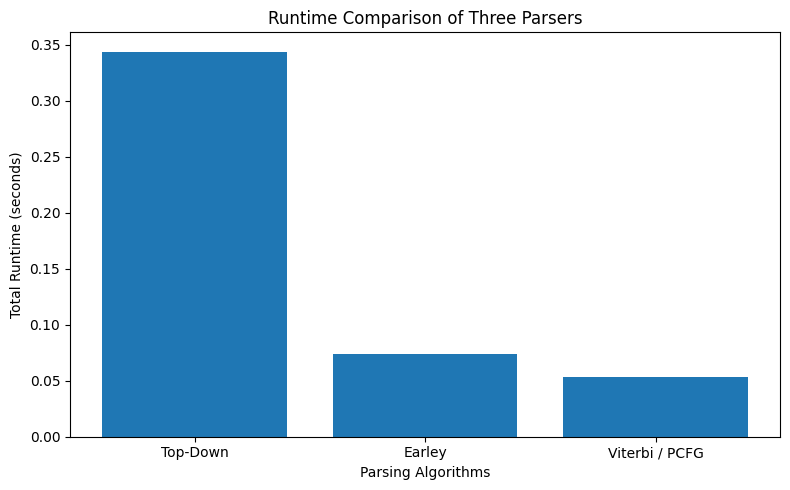

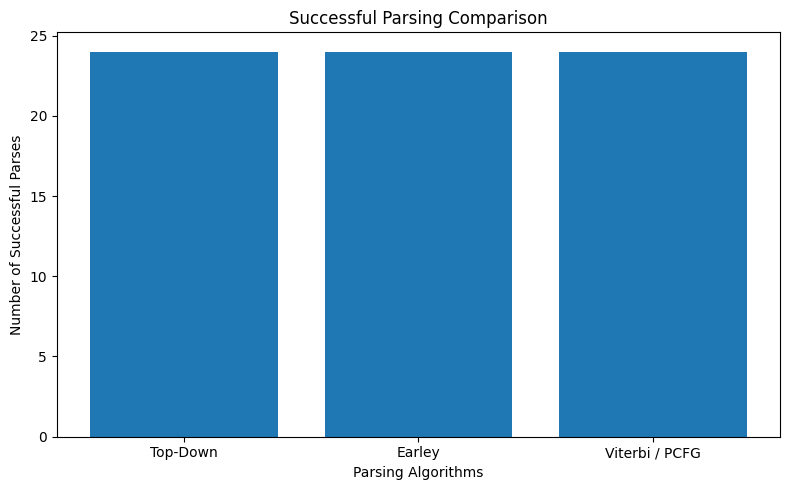

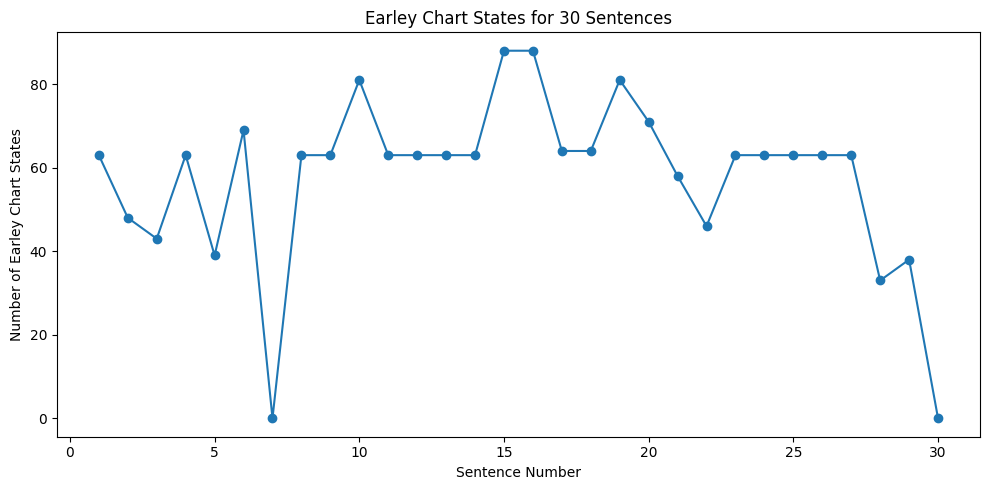


CSV files created successfully.

10. FINAL CONCLUSION
Total sentences tested: 30

Top-Down successful parses: 24
Earley successful parses: 24
Viterbi successful parses: 24

All three parsing algorithms were tested.
Runtime and parsing results were recorded.
Performance graphs and CSV files were generated.


In [ ]:

# ============================================================
# TASK 10: IMPLEMENTATION AND COMPARISON OF THREE PARSERS
# Top-Down | Earley | Viterbi / PCFG
# ============================================================

!pip -q install nltk pandas matplotlib

import nltk
import pandas as pd
import matplotlib.pyplot as plt
import time

from collections import defaultdict
from itertools import islice
from nltk import CFG, Nonterminal
from nltk.grammar import PCFG, ProbabilisticProduction
from nltk.parse import (
    RecursiveDescentParser,
    EarleyChartParser,
    ViterbiParser
)

# ============================================================
# 1. CREATE DATASET OF 30 SENTENCES
# ============================================================

sentences = [
    "the student submitted the form",
    "the portal crashed",
    "submit the application",
    "the student saw the teacher",
    "send me the receipt",
    "the student applied for a hostel",
    "tell me the fee",
    "the teacher checked the application",
    "the student booked a room",
    "i saw the student with a telescope",
    "the student submitted the report",
    "the portal displayed the result",
    "the teacher approved the request",
    "the student checked the status",
    "the student saw the form with a receipt",
    "the student submitted the form with a receipt",
    "the application is approved",
    "the student is waiting",
    "the student will submit the form",
    "will the student submit the form",
    "when will the examination begin",
    "where is the university office",
    "the student asked the teacher",
    "the teacher informed the student",
    "the student received the receipt",
    "the student submit the form",
    "the portal crashed the form",
    "submit the",
    "the student the form submitted",
    "the student submitted the form today"
]

print("=" * 75)
print("1. DATASET OF 30 UNIVERSITY HELPDESK SENTENCES")
print("=" * 75)

dataset = pd.DataFrame({
    "No.": range(1, 31),
    "Sentence": sentences
})

print(dataset.to_string(index=False))

# ============================================================
# 2. DEFINE CONTEXT-FREE GRAMMAR
# ============================================================

grammar_text = """
S -> NP VP
S -> VP
S -> AUX NP VP
S -> WH AUX NP VP
S -> NP AUX VP

NP -> DET N
NP -> DET N PP
NP -> PRON

VP -> V
VP -> V NP
VP -> V NP PP
VP -> V PP
VP -> AUX V
VP -> AUX V NP
VP -> V NP COMP S

PP -> PREP NP

DET -> 'the' | 'a'
N -> 'student' | 'teacher' | 'portal' | 'form' | 'application'
N -> 'receipt' | 'hostel' | 'room' | 'result' | 'status'
N -> 'request' | 'report' | 'telescope' | 'fee' | 'university'
N -> 'office' | 'examination' | 'library'

PRON -> 'i' | 'me'

V -> 'submitted' | 'submit' | 'crashed' | 'saw'
V -> 'send' | 'applied' | 'booked' | 'checked'
V -> 'approved' | 'displayed' | 'waiting' | 'begin'
V -> 'asked' | 'informed' | 'received'

AUX -> 'is' | 'will'
WH -> 'when' | 'where'

PREP -> 'with' | 'for'
COMP -> 'that'
"""

grammar = CFG.fromstring(grammar_text)

print("\n" + "=" * 75)
print("2. CFG GRAMMAR")
print("=" * 75)

print(grammar)

# ============================================================
# 3. CREATE PCFG FROM THE SAME GRAMMAR
# ============================================================

# Assign equal probabilities to the alternatives
# belonging to each left-hand-side non-terminal.

grouped_rules = defaultdict(list)

for production in grammar.productions():
    grouped_rules[production.lhs()].append(production)

probabilistic_rules = []

for lhs, rules in grouped_rules.items():
    probability = 1.0 / len(rules)

    for rule in rules:
        probabilistic_rules.append(
            ProbabilisticProduction(
                rule.lhs(),
                rule.rhs(),
                prob=probability
            )
        )

pcfg = PCFG(
    Nonterminal("S"),
    probabilistic_rules
)

print("\n" + "=" * 75)
print("3. PCFG RULE PROBABILITIES")
print("=" * 75)

for rule in pcfg.productions():
    print(rule)

# ============================================================
# 4. INITIALIZE THREE PARSERS
# ============================================================

topdown_parser = RecursiveDescentParser(grammar)

earley_parser = EarleyChartParser(grammar)

viterbi_parser = ViterbiParser(pcfg)

# ============================================================
# 5. PARSING FUNCTION
# ============================================================

def run_parser(parser, sentence, parser_name):

    words = sentence.split()

    start_time = time.perf_counter()

    try:

        if parser_name == "Earley":

            chart = parser.chart_parse(words)

            chart_states = chart.num_edges()

            trees = list(
                islice(parser.parse(words), 101)
            )

            parse_count = len(trees)

            if parse_count == 101:
                count_label = "100+ (capped)"
            else:
                count_label = str(parse_count)

        else:

            trees = list(
                islice(parser.parse(words), 101)
            )

            parse_count = len(trees)
            chart_states = None

            if parse_count == 101:
                count_label = "100+ (capped)"
            else:
                count_label = str(parse_count)

        elapsed_time = (
            time.perf_counter() - start_time
        )

        found = parse_count > 0

        return {
            "Found": found,
            "Parses": parse_count,
            "Parse Label": count_label,
            "States": chart_states,
            "Time": elapsed_time,
            "Error": ""
        }

    except (ValueError, RecursionError) as error:

        elapsed_time = (
            time.perf_counter() - start_time
        )

        return {
            "Found": False,
            "Parses": 0,
            "Parse Label": "0",
            "States": None,
            "Time": elapsed_time,
            "Error": str(error)
        }

# ============================================================
# 6. TEST ALL 30 SENTENCES WITH ALL THREE PARSERS
# ============================================================

print("\n" + "=" * 75)
print("4. RUNNING ALL THREE PARSERS")
print("=" * 75)

results = []

for number, sentence in enumerate(sentences, 1):

    print(f"\nProcessing Sentence {number}: {sentence}")

    top_result = run_parser(
        topdown_parser, sentence, "Top-Down"
    )

    earley_result = run_parser(
        earley_parser, sentence, "Earley"
    )

    viterbi_result = run_parser(
        viterbi_parser, sentence, "Viterbi"
    )

    results.append({
        "No.": number,
        "Sentence": sentence,

        "Top-Down Found": top_result["Found"],
        "Top-Down Parses": top_result["Parse Label"],
        "Top-Down Time": top_result["Time"],

        "Earley Found": earley_result["Found"],
        "Earley Parses": earley_result["Parse Label"],
        "Earley States": earley_result["States"],
        "Earley Time": earley_result["Time"],

        "Viterbi Found": viterbi_result["Found"],
        "Viterbi Parses": viterbi_result["Parse Label"],
        "Viterbi Time": viterbi_result["Time"]
    })

    print("Top-Down:", top_result["Found"])
    print("Earley:", earley_result["Found"])
    print("Viterbi:", viterbi_result["Found"])

results_df = pd.DataFrame(results)

# ============================================================
# 7. DISPLAY DETAILED RESULTS TABLE
# ============================================================

print("\n" + "=" * 75)
print("5. DETAILED PARSING RESULTS")
print("=" * 75)

print(results_df.to_string(index=False))

# ============================================================
# 8. OVERALL PERFORMANCE COMPARISON
# ============================================================

summary = pd.DataFrame([
    {
        "Parser": "Top-Down",
        "Successful Parses": results_df["Top-Down Found"].sum(),
        "Total Runtime (seconds)": results_df["Top-Down Time"].sum()
    },
    {
        "Parser": "Earley",
        "Successful Parses": results_df["Earley Found"].sum(),
        "Total Runtime (seconds)": results_df["Earley Time"].sum()
    },
    {
        "Parser": "Viterbi / PCFG",
        "Successful Parses": results_df["Viterbi Found"].sum(),
        "Total Runtime (seconds)": results_df["Viterbi Time"].sum()
    }
])

print("\n" + "=" * 75)
print("6. OVERALL PERFORMANCE SUMMARY")
print("=" * 75)

print(summary.to_string(index=False))

# ============================================================
# 9. AMBIGUOUS SENTENCE TEST
# ============================================================

print("\n" + "=" * 75)
print("7. AMBIGUOUS SENTENCE TEST")
print("=" * 75)

ambiguous_sentence = "i saw the student with a telescope"

for name, parser in [
    ("Top-Down", topdown_parser),
    ("Earley", earley_parser),
    ("Viterbi", viterbi_parser)
]:

    output = run_parser(
        parser, ambiguous_sentence, name
    )

    print("\nParser:", name)
    print("Sentence:", ambiguous_sentence)
    print("Parse found:", output["Found"])
    print("Number of parses:", output["Parse Label"])

# ============================================================
# 10. LEFT RECURSION TEST
# ============================================================

print("\n" + "=" * 75)
print("8. LEFT RECURSION TEST")
print("=" * 75)

left_recursive_grammar = CFG.fromstring("""
S -> NP
NP -> NP PP
NP -> N
PP -> PREP N
N -> 'student' | 'college'
PREP -> 'near'
""")

left_sentence = "student near college".split()

left_earley = EarleyChartParser(
    left_recursive_grammar
)

left_chart = left_earley.chart_parse(left_sentence)

left_trees = list(
    left_earley.parse(left_sentence)
)

print("Sentence:", " ".join(left_sentence))
print("Earley parse count:", len(left_trees))
print("Earley chart states:", left_chart.num_edges())

print("Top-Down limitation:")
print("The basic recursive-descent parser may enter")
print("infinite recursion with a left-recursive grammar.")

# ============================================================
# 11. PERFORMANCE GRAPH - RUNTIME
# ============================================================

print("\n" + "=" * 75)
print("9. PERFORMANCE GRAPH - RUNTIME")
print("=" * 75)

plt.figure(figsize=(8, 5))

plt.bar(
    summary["Parser"],
    summary["Total Runtime (seconds)"]
)

plt.xlabel("Parsing Algorithms")
plt.ylabel("Total Runtime (seconds)")
plt.title("Runtime Comparison of Three Parsers")

plt.tight_layout()
plt.show()

# ============================================================
# 12. PERFORMANCE GRAPH - SUCCESSFUL PARSES
# ============================================================

plt.figure(figsize=(8, 5))

plt.bar(
    summary["Parser"],
    summary["Successful Parses"]
)

plt.xlabel("Parsing Algorithms")
plt.ylabel("Number of Successful Parses")
plt.title("Successful Parsing Comparison")

plt.tight_layout()
plt.show()

# ============================================================
# 13. EARLEY CHART STATES GRAPH
# ============================================================

earley_states = results_df["Earley States"].fillna(0)

plt.figure(figsize=(10, 5))

plt.plot(
    results_df["No."],
    earley_states,
    marker="o"
)

plt.xlabel("Sentence Number")
plt.ylabel("Number of Earley Chart States")
plt.title("Earley Chart States for 30 Sentences")

plt.tight_layout()
plt.show()

# ============================================================
# 14. EXPORT RESULTS TO CSV
# ============================================================

results_df.to_csv(
    "Task10_Parsing_Results.csv",
    index=False
)

summary.to_csv(
    "Task10_Performance_Summary.csv",
    index=False
)

print("\nCSV files created successfully.")

# ============================================================
# 15. FINAL CONCLUSION
# ============================================================

print("\n" + "=" * 75)
print("10. FINAL CONCLUSION")
print("=" * 75)

print("Total sentences tested:", len(sentences))

print("\nTop-Down successful parses:",
      int(results_df["Top-Down Found"].sum()))

print("Earley successful parses:",
      int(results_df["Earley Found"].sum()))

print("Viterbi successful parses:",
      int(results_df["Viterbi Found"].sum()))

print("\nAll three parsing algorithms were tested.")
print("Runtime and parsing results were recorded.")
print("Performance graphs and CSV files were generated.")


1. CONTEXT-FREE GRAMMAR
Grammar with 31 productions (start state = S)
    S -> NP VP
    S -> VP
    NP -> DET N
    NP -> PRON
    NP -> NP PP
    VP -> V
    VP -> V NP
    VP -> V NP PP
    VP -> VP PP
    PP -> PREP NP
    DET -> 'the'
    DET -> 'a'
    N -> 'student'
    N -> 'teacher'
    N -> 'portal'
    N -> 'form'
    N -> 'telescope'
    N -> 'room'
    N -> 'hostel'
    N -> 'receipt'
    PRON -> 'i'
    PRON -> 'me'
    V -> 'submitted'
    V -> 'submit'
    V -> 'crashed'
    V -> 'saw'
    V -> 'send'
    V -> 'booked'
    V -> 'applied'
    PREP -> 'with'
    PREP -> 'for'

2. TEST SENTENCES
1 the student submitted the form
2 the portal crashed
3 submit the form
4 the student saw the teacher
5 i saw the student with a telescope
6 the student applied for a hostel
7 send me the receipt
8 the student booked a room
9 the student submit the form
10 the portal crashed the form

3. PARSER COMPARISON RESULTS
                          Sentence  Top-Down  Earley  PCFG/Viterbi  T

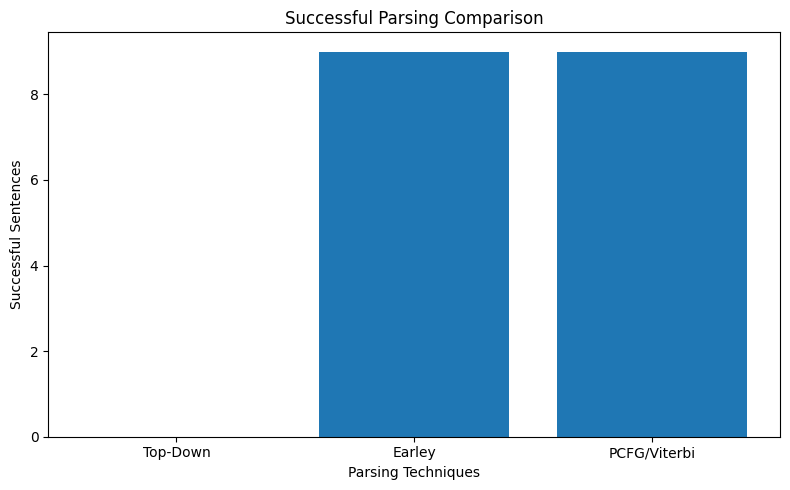

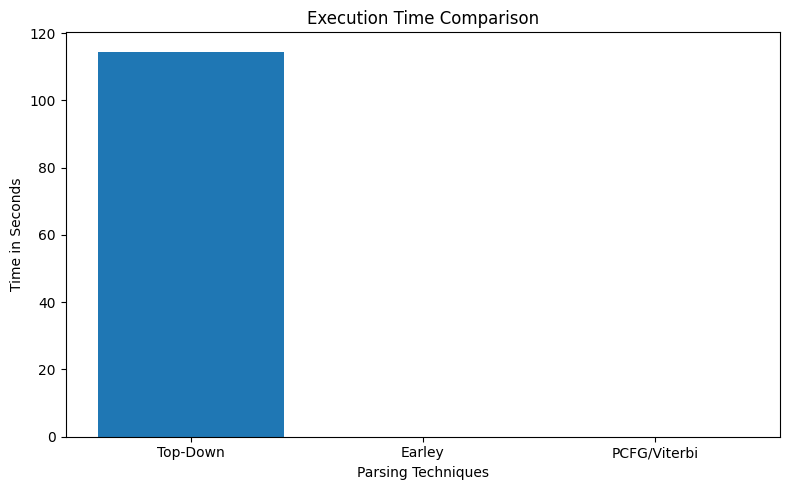


7. RECOMMENDED PARSING ARCHITECTURE

University Helpdesk Query
          |
          v
Feature-Based CFG
          |
          v
Earley Parser
          |
          v
PCFG / Viterbi Ranking
          |
          v
Best Parse Tree
          |
          v
Structured Query Interpretation

Reasons for recommendation:
1. Feature-based CFG checks grammatical constraints.
2. Earley handles ambiguity and left recursion.
3. PCFG ranks alternative parse trees.
4. Viterbi selects the highest-probability parse.

FINAL CONCLUSION
Top-Down parsing is simple for basic sentences.
Earley parsing handles complex grammar structures.
PCFG/Viterbi ranks alternative interpretations.
Recommended: Feature-Based CFG + Earley + PCFG.
Actual performance depends on grammar coverage and data.


In [ ]:

# ============================================================
# TASK 11: COMPARISON AND RECOMMENDATION OF PARSING TECHNIQUES
# ============================================================

!pip -q install nltk pandas matplotlib

import nltk
import pandas as pd
import matplotlib.pyplot as plt
import time

from collections import defaultdict
from itertools import islice
from nltk import CFG, Nonterminal
from nltk.grammar import PCFG, ProbabilisticProduction
from nltk.parse import (
    RecursiveDescentParser,
    EarleyChartParser,
    ViterbiParser
)

# ------------------------------------------------------------
# 1. DEFINE CFG GRAMMAR
# ------------------------------------------------------------

grammar = CFG.fromstring("""
S -> NP VP
S -> VP

NP -> DET N
NP -> PRON
NP -> NP PP

VP -> V
VP -> V NP
VP -> V NP PP
VP -> VP PP

PP -> PREP NP

DET -> 'the' | 'a'
N -> 'student' | 'teacher' | 'portal' | 'form'
N -> 'telescope' | 'room' | 'hostel' | 'receipt'
PRON -> 'i' | 'me'
V -> 'submitted' | 'submit' | 'crashed' | 'saw'
V -> 'send' | 'booked' | 'applied'
PREP -> 'with' | 'for'
""")

print("=" * 65)
print("1. CONTEXT-FREE GRAMMAR")
print("=" * 65)
print(grammar)

# ------------------------------------------------------------
# 2. CREATE PCFG
# ------------------------------------------------------------

grouped = defaultdict(list)

for rule in grammar.productions():
    grouped[rule.lhs()].append(rule)

probabilistic_rules = []

for lhs, rules in grouped.items():
    p = 1 / len(rules)

    for rule in rules:
        probabilistic_rules.append(
            ProbabilisticProduction(
                rule.lhs(), rule.rhs(), prob=p
            )
        )

pcfg = PCFG(
    Nonterminal("S"),
    probabilistic_rules
)

# ------------------------------------------------------------
# 3. INITIALIZE PARSERS
# ------------------------------------------------------------

top_down = RecursiveDescentParser(grammar)
earley = EarleyChartParser(grammar)
viterbi = ViterbiParser(pcfg)

# ------------------------------------------------------------
# 4. TEST SENTENCES
# ------------------------------------------------------------

test_sentences = [
    "the student submitted the form",
    "the portal crashed",
    "submit the form",
    "the student saw the teacher",
    "i saw the student with a telescope",
    "the student applied for a hostel",
    "send me the receipt",
    "the student booked a room",
    "the student submit the form",
    "the portal crashed the form"
]

print("\n" + "=" * 65)
print("2. TEST SENTENCES")
print("=" * 65)

for i, sentence in enumerate(test_sentences, 1):
    print(i, sentence)

# ------------------------------------------------------------
# 5. RUN ALL THREE PARSERS
# ------------------------------------------------------------

results = []

def test_parser(parser, sentence, parser_type):

    words = sentence.split()
    start = time.perf_counter()

    try:
        if parser_type == "Earley":
            chart = parser.chart_parse(words)
            states = chart.num_edges()
            trees = list(islice(parser.parse(words), 101))
        else:
            states = None
            trees = list(islice(parser.parse(words), 101))

        elapsed = time.perf_counter() - start

        return {
            "Accepted": len(trees) > 0,
            "Parse Count": (
                "100+" if len(trees) == 101 else len(trees)
            ),
            "States": states,
            "Time": elapsed
        }

    except (ValueError, RecursionError):
        return {
            "Accepted": False,
            "Parse Count": 0,
            "States": None,
            "Time": time.perf_counter() - start
        }


for sentence in test_sentences:

    td = test_parser(top_down, sentence, "Top-Down")
    er = test_parser(earley, sentence, "Earley")
    pc = test_parser(viterbi, sentence, "Viterbi")

    results.append({
        "Sentence": sentence,
        "Top-Down": td["Accepted"],
        "Earley": er["Accepted"],
        "PCFG/Viterbi": pc["Accepted"],
        "Top-Down Parses": td["Parse Count"],
        "Earley Parses": er["Parse Count"],
        "Viterbi Parses": pc["Parse Count"],
        "Earley States": er["States"],
        "Top-Down Time": td["Time"],
        "Earley Time": er["Time"],
        "Viterbi Time": pc["Time"]
    })

result_df = pd.DataFrame(results)

# ------------------------------------------------------------
# 6. DISPLAY COMPARISON TABLE
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("3. PARSER COMPARISON RESULTS")
print("=" * 65)

print(result_df.to_string(index=False))

# ------------------------------------------------------------
# 7. OVERALL PERFORMANCE SUMMARY
# ------------------------------------------------------------

summary = pd.DataFrame({
    "Parser": ["Top-Down", "Earley", "PCFG/Viterbi"],
    "Successful Sentences": [
        result_df["Top-Down"].sum(),
        result_df["Earley"].sum(),
        result_df["PCFG/Viterbi"].sum()
    ],
    "Total Runtime": [
        result_df["Top-Down Time"].sum(),
        result_df["Earley Time"].sum(),
        result_df["Viterbi Time"].sum()
    ]
})

print("\n" + "=" * 65)
print("4. OVERALL PERFORMANCE")
print("=" * 65)
print(summary.to_string(index=False))

# ------------------------------------------------------------
# 8. FEATURE-BASED GRAMMAR CHECK
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("5. FEATURE-BASED GRAMMAR DEMONSTRATION")
print("=" * 65)

lexicon = {
    "student": {"NUM": "singular", "PER": 3},
    "students": {"NUM": "plural", "PER": 3},
    "submits": {"NUM": "singular", "PER": 3},
    "submit": {"NUM": "plural", "PER": 3}
}

def check_agreement(subject, verb):

    if subject not in lexicon or verb not in lexicon:
        return False

    return (
        lexicon[subject]["NUM"] == lexicon[verb]["NUM"]
        and lexicon[subject]["PER"] == lexicon[verb]["PER"]
    )

feature_tests = [
    ("student", "submits"),
    ("students", "submit"),
    ("student", "submit"),
    ("students", "submits")
]

for subject, verb in feature_tests:
    result = check_agreement(subject, verb)

    print(
        subject, "+", verb,
        "->",
        "Accepted" if result else "Rejected"
    )

# ------------------------------------------------------------
# 9. AMBIGUITY TEST
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("6. AMBIGUITY TEST")
print("=" * 65)

ambiguous = "i saw the student with a telescope"

for name, parser in [
    ("Top-Down", top_down),
    ("Earley", earley),
    ("PCFG/Viterbi", viterbi)
]:

    try:
        trees = list(islice(parser.parse(ambiguous.split()), 101))

        print("\nParser:", name)
        print("Sentence:", ambiguous)
        print("Number of parses:",
              "100+" if len(trees) == 101 else len(trees))

        if trees:
            print("One available parse tree:")
            trees[0].pretty_print()

    except (ValueError, RecursionError):
        print(name, "could not parse the sentence.")

# ------------------------------------------------------------
# 10. PERFORMANCE GRAPH - SUCCESSFUL PARSES
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.bar(
    summary["Parser"],
    summary["Successful Sentences"]
)

plt.title("Successful Parsing Comparison")
plt.xlabel("Parsing Techniques")
plt.ylabel("Successful Sentences")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 11. PERFORMANCE GRAPH - EXECUTION TIME
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.bar(
    summary["Parser"],
    summary["Total Runtime"]
)

plt.title("Execution Time Comparison")
plt.xlabel("Parsing Techniques")
plt.ylabel("Time in Seconds")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 12. RECOMMENDED ARCHITECTURE
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("7. RECOMMENDED PARSING ARCHITECTURE")
print("=" * 65)

print("""
University Helpdesk Query
          |
          v
Feature-Based CFG
          |
          v
Earley Parser
          |
          v
PCFG / Viterbi Ranking
          |
          v
Best Parse Tree
          |
          v
Structured Query Interpretation
""")

print("Reasons for recommendation:")
print("1. Feature-based CFG checks grammatical constraints.")
print("2. Earley handles ambiguity and left recursion.")
print("3. PCFG ranks alternative parse trees.")
print("4. Viterbi selects the highest-probability parse.")

# ------------------------------------------------------------
# 13. FINAL CONCLUSION
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("FINAL CONCLUSION")
print("=" * 65)

print("Top-Down parsing is simple for basic sentences.")
print("Earley parsing handles complex grammar structures.")
print("PCFG/Viterbi ranks alternative interpretations.")
print("Recommended: Feature-Based CFG + Earley + PCFG.")
print("Actual performance depends on grammar coverage and data.")


1. ORIGINAL GRAMMAR
Grammar with 28 productions (start state = S)
    S -> NP VP
    S -> VP
    NP -> DET N
    NP -> PRON
    VP -> V
    VP -> V NP
    VP -> V NP PP
    VP -> V PP
    PP -> PREP NP
    DET -> 'the'
    DET -> 'a'
    N -> 'student'
    N -> 'application'
    N -> 'result'
    N -> 'exam'
    N -> 'hostel'
    N -> 'fee'
    PRON -> 'i'
    PRON -> 'me'
    PRON -> 'you'
    V -> 'submitted'
    V -> 'wants'
    V -> 'tell'
    V -> 'begin'
    V -> 'saw'
    V -> 'applied'
    PREP -> 'with'
    PREP -> 'for'

2. NEW CONVERSATIONAL MESSAGES
1 can you tell me when the exams will begin
2 the student who submitted the application wants the result
3 can you tell me when exams begin and whether hostel fee is due

3. ORIGINAL GRAMMAR TEST RESULTS

Message: can you tell me when the exams will begin
Accepted: False
Chart States: 0

Message: the student who submitted the application wants the result
Accepted: False
Chart States: 0

Message: can you tell me when exams begin 

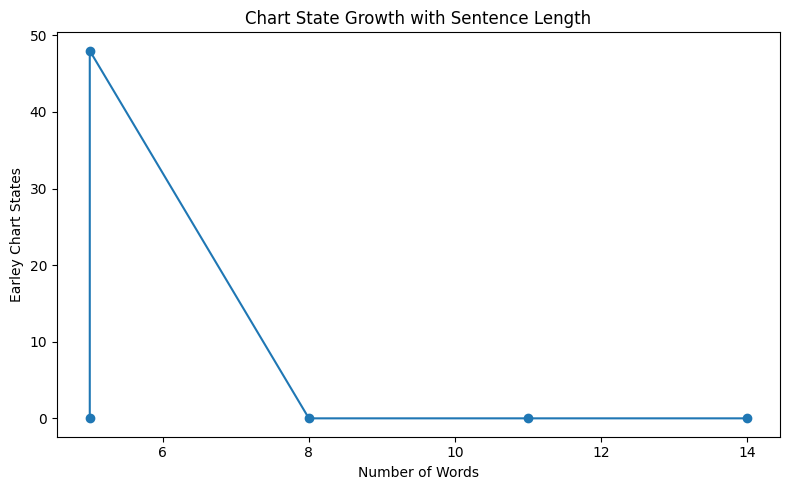

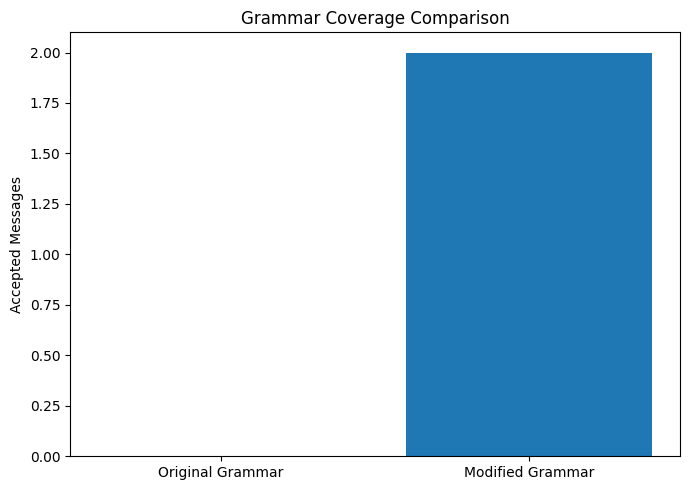


10. REVISED SYSTEM ARCHITECTURE

Incoming Conversational Message
             |
             v
       Text Preprocessing
             |
             v
     Extended Feature-Based CFG
             |
             v
         Earley Parser
             |
             v
       PCFG / Viterbi
             |
             v
        Best Parse Tree
             |
             v
    Structured Helpdesk Query


11. FINAL RESULTS AND CONCLUSION
Total new messages tested: 3
Original grammar accepted: 0
Modified grammar accepted: 2
Ambiguous parse trees: 2

CONCLUSION:

1. The original grammar has limited coverage.
2. New rules improve conversational sentence coverage.
3. Relative clauses need additional grammar rules.
4. Embedded questions require clause-level rules.
5. Coordination requires additional grammar structures.
6. Earley parsing handles complex and ambiguous structures.
7. Feature structures check grammatical constraints.
8. PCFG/Viterbi can rank alternative parse trees.

The recommende

In [ ]:

# ============================================================
# TASK 12: DAY-4 DESIGN CHALLENGE
# RE-EVALUATING AND REDESIGNING THE PARSING SYSTEM
# ============================================================

!pip -q install nltk pandas matplotlib

import nltk
import pandas as pd
import matplotlib.pyplot as plt
import time

from itertools import islice
from nltk import CFG
from nltk.parse import EarleyChartParser

# ============================================================
# 1. ORIGINAL GRAMMAR
# ============================================================

original_grammar = CFG.fromstring("""
S -> NP VP
S -> VP

NP -> DET N
NP -> PRON

VP -> V
VP -> V NP
VP -> V NP PP
VP -> V PP

PP -> PREP NP

DET -> 'the' | 'a'
N -> 'student' | 'application' | 'result'
N -> 'exam' | 'hostel' | 'fee'
PRON -> 'i' | 'me' | 'you'
V -> 'submitted' | 'wants' | 'tell' | 'begin'
V -> 'saw' | 'applied'
PREP -> 'with' | 'for'
""")

original_parser = EarleyChartParser(original_grammar)

print("=" * 70)
print("1. ORIGINAL GRAMMAR")
print("=" * 70)

print(original_grammar)

# ============================================================
# 2. THREE NEW CONVERSATIONAL MESSAGES
# ============================================================

messages = [
    "can you tell me when the exams will begin",
    "the student who submitted the application wants the result",
    "can you tell me when exams begin and whether hostel fee is due"
]

print("\n" + "=" * 70)
print("2. NEW CONVERSATIONAL MESSAGES")
print("=" * 70)

for i, message in enumerate(messages, 1):
    print(i, message)

# ============================================================
# 3. TEST ORIGINAL GRAMMAR
# ============================================================

def test_grammar(parser, sentence):

    words = sentence.lower().split()
    start = time.perf_counter()

    try:
        chart = parser.chart_parse(words)
        states = chart.num_edges()

        trees = list(
            islice(parser.parse(words), 101)
        )

        elapsed = time.perf_counter() - start

        return {
            "Accepted": len(trees) > 0,
            "Parse Count": len(trees),
            "Chart States": states,
            "Runtime": elapsed,
            "Error": ""
        }

    except (ValueError, RecursionError) as error:

        return {
            "Accepted": False,
            "Parse Count": 0,
            "Chart States": 0,
            "Runtime": time.perf_counter() - start,
            "Error": str(error)
        }


print("\n" + "=" * 70)
print("3. ORIGINAL GRAMMAR TEST RESULTS")
print("=" * 70)

original_results = []

for message in messages:

    result = test_grammar(
        original_parser, message
    )

    original_results.append({
        "Message": message,
        "Accepted": result["Accepted"],
        "Parse Count": result["Parse Count"],
        "Chart States": result["Chart States"],
        "Runtime": result["Runtime"]
    })

    print("\nMessage:", message)
    print("Accepted:", result["Accepted"])
    print("Chart States:", result["Chart States"])

original_df = pd.DataFrame(original_results)

print("\nOriginal Grammar Results:")
print(original_df.to_string(index=False))

# ============================================================
# 4. MODIFIED GRAMMAR
# Supports:
# Embedded questions
# Relative clauses
# Coordinated embedded questions
# ============================================================

modified_grammar = CFG.fromstring("""
S -> NP VP
S -> AUX NP VP

NP -> DET N
NP -> DET N REL
NP -> PRON
NP -> N

REL -> RELPRON V NP

VP -> V
VP -> V NP
VP -> V NP CP

CP -> WH NP AUX V
CP -> WH NP V CONJ WH NP AUX ADJ

DET -> 'the' | 'a'
N -> 'student' | 'application' | 'result'
N -> 'exams' | 'exam' | 'hostel' | 'fee'
N -> 'you'
PRON -> 'me' | 'i'
RELPRON -> 'who'

AUX -> 'can' | 'will' | 'is'
WH -> 'when' | 'whether'
CONJ -> 'and'

V -> 'tell' | 'submitted' | 'wants'
V -> 'begin' | 'saw'

ADJ -> 'due'
""")

modified_parser = EarleyChartParser(modified_grammar)

print("\n" + "=" * 70)
print("4. MODIFIED GRAMMAR")
print("=" * 70)

print(modified_grammar)

# ============================================================
# 5. TEST MODIFIED GRAMMAR
# ============================================================

print("\n" + "=" * 70)
print("5. MODIFIED GRAMMAR TEST RESULTS")
print("=" * 70)

modified_results = []

for message in messages:

    result = test_grammar(
        modified_parser, message
    )

    modified_results.append({
        "Message": message,
        "Accepted": result["Accepted"],
        "Parse Count": result["Parse Count"],
        "Chart States": result["Chart States"],
        "Runtime": result["Runtime"]
    })

    print("\nMessage:", message)
    print("Accepted:", result["Accepted"])
    print("Parse Count:", result["Parse Count"])
    print("Chart States:", result["Chart States"])

    if result["Accepted"]:
        trees = list(
            islice(
                modified_parser.parse(message.split()),
                1
            )
        )

        print("Example Parse Tree:")
        trees[0].pretty_print()

modified_df = pd.DataFrame(modified_results)

# ============================================================
# 6. ORIGINAL VS MODIFIED COMPARISON
# ============================================================

print("\n" + "=" * 70)
print("6. ORIGINAL VS MODIFIED GRAMMAR")
print("=" * 70)

comparison = pd.DataFrame({
    "Message": messages,
    "Original Accepted": original_df["Accepted"],
    "Modified Accepted": modified_df["Accepted"],
    "Original States": original_df["Chart States"],
    "Modified States": modified_df["Chart States"]
})

print(comparison.to_string(index=False))

# ============================================================
# 7. FEATURE-BASED CONSTRAINT CHECK
# ============================================================

print("\n" + "=" * 70)
print("7. FEATURE-BASED GRAMMAR CHECK")
print("=" * 70)

lexicon = {
    "student": {"NUM": "singular", "PER": 3},
    "students": {"NUM": "plural", "PER": 3},
    "wants": {"NUM": "singular", "PER": 3},
    "want": {"NUM": "plural", "PER": 3}
}

def check_agreement(subject, verb):

    if subject not in lexicon or verb not in lexicon:
        return False

    return (
        lexicon[subject]["NUM"] == lexicon[verb]["NUM"]
        and lexicon[subject]["PER"] == lexicon[verb]["PER"]
    )

feature_tests = [
    ("student", "wants"),
    ("students", "want"),
    ("student", "want"),
    ("students", "wants")
]

for subject, verb in feature_tests:

    valid = check_agreement(subject, verb)

    print(
        subject, "+", verb,
        "->",
        "Accepted" if valid else "Rejected"
    )

# ============================================================
# 8. AMBIGUITY TEST
# ============================================================

print("\n" + "=" * 70)
print("8. AMBIGUITY TEST")
print("=" * 70)

ambiguity_grammar = CFG.fromstring("""
S -> NP VP
NP -> PRON | DET N | NP PP
VP -> V NP | VP PP
PP -> PREP NP

PRON -> 'i'
DET -> 'the' | 'a'
N -> 'student' | 'telescope'
V -> 'saw'
PREP -> 'with'
""")

ambiguity_parser = EarleyChartParser(
    ambiguity_grammar
)

ambiguous_sentence = "i saw the student with a telescope"

ambiguous_trees = list(
    ambiguity_parser.parse(
        ambiguous_sentence.split()
    )
)

print("Sentence:", ambiguous_sentence)
print("Number of parse trees:", len(ambiguous_trees))

for i, tree in enumerate(ambiguous_trees, 1):
    print("\nParse Tree", i)
    tree.pretty_print()

# ============================================================
# 9. CHART GROWTH WITH SENTENCE LENGTH
# ============================================================

print("\n" + "=" * 70)
print("9. CHART STATE GROWTH")
print("=" * 70)

growth_sentences = [
    "the student submitted the form",
    "the student submitted the application",
    "the student submitted the application with the result",
    "the student submitted the application with the result with the form",
    "the student submitted the application with the result with the form with the hostel"
]

growth_results = []

for sentence in growth_sentences:

    result = test_grammar(
        modified_parser, sentence
    )

    growth_results.append({
        "Sentence Length": len(sentence.split()),
        "Chart States": result["Chart States"],
        "Accepted": result["Accepted"]
    })

growth_df = pd.DataFrame(growth_results)

print(growth_df.to_string(index=False))

# ============================================================
# 10. CHART GROWTH GRAPH
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    growth_df["Sentence Length"],
    growth_df["Chart States"],
    marker="o"
)

plt.xlabel("Number of Words")
plt.ylabel("Earley Chart States")
plt.title("Chart State Growth with Sentence Length")

plt.tight_layout()
plt.show()

# ============================================================
# 11. ORIGINAL VS MODIFIED ACCEPTANCE GRAPH
# ============================================================

original_count = int(
    original_df["Accepted"].sum()
)

modified_count = int(
    modified_df["Accepted"].sum()
)

plt.figure(figsize=(7, 5))

plt.bar(
    ["Original Grammar", "Modified Grammar"],
    [original_count, modified_count]
)

plt.ylabel("Accepted Messages")
plt.title("Grammar Coverage Comparison")

plt.tight_layout()
plt.show()

# ============================================================
# 12. REVISED SYSTEM ARCHITECTURE
# ============================================================

print("\n" + "=" * 70)
print("10. REVISED SYSTEM ARCHITECTURE")
print("=" * 70)

print("""
Incoming Conversational Message
             |
             v
       Text Preprocessing
             |
             v
     Extended Feature-Based CFG
             |
             v
         Earley Parser
             |
             v
       PCFG / Viterbi
             |
             v
        Best Parse Tree
             |
             v
    Structured Helpdesk Query
""")

# ============================================================
# 13. FINAL RESULTS
# ============================================================

print("\n" + "=" * 70)
print("11. FINAL RESULTS AND CONCLUSION")
print("=" * 70)

print("Total new messages tested:", len(messages))

print("Original grammar accepted:",
      original_count)

print("Modified grammar accepted:",
      modified_count)

print("Ambiguous parse trees:",
      len(ambiguous_trees))

print("""
CONCLUSION:

1. The original grammar has limited coverage.
2. New rules improve conversational sentence coverage.
3. Relative clauses need additional grammar rules.
4. Embedded questions require clause-level rules.
5. Coordination requires additional grammar structures.
6. Earley parsing handles complex and ambiguous structures.
7. Feature structures check grammatical constraints.
8. PCFG/Viterbi can rank alternative parse trees.

The recommended solution is to modify the original
Feature-Based CFG + Earley + PCFG architecture.
""")

# ============================================================
# 14. SAVE RESULTS
# ============================================================

comparison.to_csv(
    "Task12_Grammar_Comparison.csv",
    index=False
)

growth_df.to_csv(
    "Task12_Chart_Growth.csv",
    index=False
)

print("Task 12 result files saved successfully.")
